# Satellite Building Change Detection (LEVIR-CD)

CS57600 Machine Learning, Fall 2026 · Raviteja Gundu, Joel Adu-Kwarteng

Predict pixel-level building-change masks from pairs of satellite images, comparing an image-difference baseline, an early-fusion U-Net (U-Net-EF) and a Siamese U-Net.

**How to run**
1. Upload this notebook to Colab and choose **Runtime → Change runtime type → T4 GPU**.
2. Run all cells. Allow Drive access when prompted.

Data, checkpoints and results are stored on Google Drive under `CONFIG["project_root"]`, so they survive between Colab sessions. Each task adds one section to this notebook.

## Task 1 · Setup

In [1]:
!nvidia-smi

Thu Oct 29 22:18:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os
import random
from dataclasses import dataclass
from pathlib import Path

import matplotlib
import numpy as np
import PIL
import torch

# All settings live here. Later tasks add their own entries (data, baseline, models).
CONFIG = {
    "project_root": "/content/drive/MyDrive/levir-change-detection",  # persistent storage
    "local_root": "/content/local",  # fast VM disk, wiped when the session ends
    "seed": 42,
    "deterministic": False,  # True makes cuDNN deterministic (slower)
}

In [4]:
def set_seed(seed: int, deterministic: bool = False) -> None:
    """Seed Python, NumPy and torch (CPU and all GPUs)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic


def seed_worker(worker_id: int) -> None:
    """DataLoader worker_init_fn: derive NumPy/Python seeds from torch's per-worker seed."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


@dataclass(frozen=True)
class Paths:
    """Standard locations under the Drive project root, plus a fast local scratch folder."""

    root: Path
    local: Path

    @property
    def raw(self) -> Path:  # LEVIR-CD as downloaded: train/val/test/{A,B,label}
        return self.root / "data" / "raw"

    @property
    def tiles_zip(self) -> Path:  # 256x256 tiles (Task 3)
        return self.root / "data" / "tiles.zip"

    @property
    def stats_file(self) -> Path:  # training-set channel mean/std (Task 4)
        return self.root / "data" / "stats.json"

    @property
    def runs(self) -> Path:  # checkpoints and logs, one folder per run
        return self.root / "runs"

    @property
    def results(self) -> Path:  # metrics JSON and CSVs
        return self.root / "results"

    @property
    def figures(self) -> Path:  # figures for the report
        return self.results / "figures"

    @property
    def local_tiles(self) -> Path:  # tiles unzipped to local disk each session
        return self.local / "tiles"

    def run_dir(self, name: str) -> Path:
        return self.runs / name

    def make_dirs(self) -> "Paths":
        for p in (self.raw, self.runs, self.results, self.figures, self.local):
            p.mkdir(parents=True, exist_ok=True)
        return self

In [5]:
if not Path("/content/drive/MyDrive").is_dir():
    raise RuntimeError("Google Drive is not mounted. Run the drive.mount cell above first.")

set_seed(CONFIG["seed"], CONFIG["deterministic"])
DEVICE = get_device()
PATHS = Paths(Path(CONFIG["project_root"]), Path(CONFIG["local_root"])).make_dirs()

print(f"torch {torch.__version__} | numpy {np.__version__} | pillow {PIL.__version__} | matplotlib {matplotlib.__version__}")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Device:", DEVICE)
print()
for name in ("root", "raw", "tiles_zip", "stats_file", "runs", "results", "figures", "local_tiles"):
    print(f"{name:>11}: {getattr(PATHS, name)}")

torch 2.11.0+cu130 | numpy 2.1.3 | pillow 11.3.0 | matplotlib 3.10.0
CUDA available: True
GPU: Tesla T4
Device: cuda

       root: /content/drive/MyDrive/levir-change-detection
        raw: /content/drive/MyDrive/levir-change-detection/data/raw
  tiles_zip: /content/drive/MyDrive/levir-change-detection/data/tiles.zip
 stats_file: /content/drive/MyDrive/levir-change-detection/data/stats.json
       runs: /content/drive/MyDrive/levir-change-detection/runs
    results: /content/drive/MyDrive/levir-change-detection/results
    figures: /content/drive/MyDrive/levir-change-detection/results/figures
local_tiles: /content/local/tiles


## Task 2 · Metrics

All metrics are for the **change** class (label 1) and come from confusion counts:

| Metric | Formula |
|---|---|
| Precision | TP / (TP + FP) |
| Recall | TP / (TP + FN) |
| F1 (= Dice) | 2·TP / (2·TP + FP + FN) |
| IoU | TP / (TP + FP + FN) |
| Accuracy | (TP + TN) / all pixels |

Dataset-level results add up the counts over every test pixel first and compute the metrics once (not an average of per-image scores).

Zero denominators: if a mask has no change and the prediction has none either (TP = FP = FN = 0), precision, recall, F1 and IoU are 1.0. Any other zero denominator gives 0.0. This mostly matters for per-image scores on no-change tiles.

Inputs must already be binary (0/1 or bool). Threshold probabilities first. Tensors are counted on their own device, so validation on the GPU never copies masks to the CPU.

In [6]:
METRIC_NAMES = ("precision", "recall", "f1", "iou", "accuracy")


def _squeeze_channel(x):
    """(N, 1, H, W) -> (N, H, W), so model outputs and masks line up."""
    return x[:, 0] if x.ndim == 4 and x.shape[1] == 1 else x


def _as_binary(x, name):
    """Return a bool tensor/array. Raises if values other than 0/1 are present."""
    if torch.is_tensor(x):
        if x.dtype != torch.bool:
            if not ((x == 0) | (x == 1)).all():
                raise ValueError(f"{name} must be binary (0/1). Threshold probabilities first.")
            x = x != 0
        return x
    x = np.asarray(x)
    if x.dtype != bool:
        if not np.isin(x, (0, 1)).all():
            raise ValueError(f"{name} must be binary (0/1). Threshold probabilities first.")
        x = x != 0
    return x


def confusion_counts(pred, target):
    """Return (tp, fp, fn, tn) as Python ints for binary masks of the same shape.

    Accepts numpy arrays or torch tensors. If either is a tensor, counting happens on
    that tensor's device.
    """
    if torch.is_tensor(pred) or torch.is_tensor(target):
        device = pred.device if torch.is_tensor(pred) else target.device
        pred = torch.as_tensor(pred, device=device)
        target = torch.as_tensor(target, device=device)
    pred, target = _squeeze_channel(pred), _squeeze_channel(target)
    if tuple(pred.shape) != tuple(target.shape):
        raise ValueError(f"Shape mismatch: pred {tuple(pred.shape)} vs target {tuple(target.shape)}")
    p, t = _as_binary(pred, "pred"), _as_binary(target, "target")
    tp = int((p & t).sum())
    fp = int((p & ~t).sum())
    fn = int((~p & t).sum())
    tn = int(t.numel() if torch.is_tensor(t) else t.size) - tp - fp - fn
    return tp, fp, fn, tn


def metrics_from_counts(tp, fp, fn, tn):
    """Precision, recall, F1, IoU and accuracy from confusion counts, plus the counts."""
    empty = tp + fp + fn == 0  # nothing to find and nothing predicted

    def ratio(num, den):
        if den == 0:
            return 1.0 if empty else 0.0
        return num / den

    total = tp + fp + fn + tn
    return {
        "precision": ratio(tp, tp + fp),
        "recall": ratio(tp, tp + fn),
        "f1": ratio(2 * tp, 2 * tp + fp + fn),
        "iou": ratio(tp, tp + fp + fn),
        "accuracy": (tp + tn) / total if total else 1.0,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


class ConfusionAccumulator:
    """Running TP/FP/FN/TN over many batches. Call compute() for dataset-level metrics."""

    def __init__(self):
        self.reset()

    def reset(self):
        self.tp = self.fp = self.fn = self.tn = 0

    def update(self, pred, target):
        tp, fp, fn, tn = confusion_counts(pred, target)
        self.tp += tp
        self.fp += fp
        self.fn += fn
        self.tn += tn
        return self

    def compute(self):
        return metrics_from_counts(self.tp, self.fp, self.fn, self.tn)

    def __repr__(self):
        return f"ConfusionAccumulator(tp={self.tp}, fp={self.fp}, fn={self.fn}, tn={self.tn})"


def per_image_metrics(pred, target, names=None):
    """Metrics for each image in a batch shaped (N, H, W) or (N, 1, H, W).

    Returns a list of dicts. If names is given, each dict also gets a "name" key.
    """
    pred, target = _squeeze_channel(pred), _squeeze_channel(target)
    if len(pred) != len(target):
        raise ValueError(f"Batch size mismatch: {len(pred)} vs {len(target)}")
    rows = []
    for i in range(len(pred)):
        row = metrics_from_counts(*confusion_counts(pred[i], target[i]))
        if names is not None:
            row = {"name": names[i], **row}
        rows.append(row)
    return rows


def format_metrics(m):
    return "  ".join(f"{k}={m[k]:.4f}" for k in METRIC_NAMES)

### Demo: hand-computed toy example

A 4×4 target with 4 changed pixels and a prediction with 4 changed pixels, 3 of them correct:
TP = 3, FP = 1, FN = 1, TN = 11, so precision = recall = F1 = 0.75, IoU = 3/5 = 0.6 and accuracy = 14/16 = 0.875.

The cell checks these values and a few other cases, and raises an error if anything is off.

In [7]:
target = np.array([[0, 0, 0, 0],
                   [0, 1, 1, 0],
                   [0, 1, 1, 0],
                   [0, 0, 0, 0]])
pred = np.array([[0, 0, 0, 0],
                 [0, 1, 1, 1],
                 [0, 1, 0, 0],
                 [0, 0, 0, 0]])


def check(label, got, expected):
    ok = all(np.isclose(got[k], v) for k, v in expected.items())
    print(f"{'OK  ' if ok else 'FAIL'} {label:<38} {format_metrics(got)}")
    if not ok:
        raise AssertionError(f"{label}: expected {expected}, got {got}")


# 1. Hand-computed example
check("toy 4x4 (numpy)", metrics_from_counts(*confusion_counts(pred, target)),
      {"tp": 3, "fp": 1, "fn": 1, "tn": 11,
       "precision": 0.75, "recall": 0.75, "f1": 0.75, "iou": 0.6, "accuracy": 0.875})

# 2. Same example as torch tensors on the GPU, shaped like model output (N, 1, H, W)
t_pred = torch.tensor(pred, device=DEVICE)[None, None]
t_target = torch.tensor(target, device=DEVICE)[None]
check(f"toy 4x4 (torch on {DEVICE.type})", metrics_from_counts(*confusion_counts(t_pred, t_target)),
      {"precision": 0.75, "recall": 0.75, "f1": 0.75, "iou": 0.6})

# 3. Edge cases
zeros, ones = np.zeros((4, 4), int), np.ones((4, 4), int)
check("no change, nothing predicted", metrics_from_counts(*confusion_counts(zeros, zeros)),
      {"precision": 1, "recall": 1, "f1": 1, "iou": 1, "accuracy": 1})
check("all change, nothing predicted", metrics_from_counts(*confusion_counts(zeros, ones)),
      {"precision": 0, "recall": 0, "f1": 0, "iou": 0, "accuracy": 0})
check("no change, everything predicted", metrics_from_counts(*confusion_counts(ones, zeros)),
      {"precision": 0, "recall": 0, "f1": 0, "iou": 0, "accuracy": 0})
check("perfect prediction", metrics_from_counts(*confusion_counts(target, target)),
      {"precision": 1, "recall": 1, "f1": 1, "iou": 1, "accuracy": 1})

# 4. Accumulating random batches equals computing on everything at once
rng = np.random.default_rng(0)
big_pred = rng.integers(0, 2, size=(10, 32, 32))
big_target = rng.integers(0, 2, size=(10, 32, 32))
acc = ConfusionAccumulator()
for start in range(0, 10, 3):  # uneven batches: 3, 3, 3, 1
    acc.update(big_pred[start:start + 3], big_target[start:start + 3])
check("batched == all at once", acc.compute(), metrics_from_counts(*confusion_counts(big_pred, big_target)))

# 5. Probabilities are rejected instead of silently miscounted
try:
    confusion_counts(np.array([[0.2, 0.9]]), np.array([[0, 1]]))
    raise AssertionError("non-binary input was accepted")
except ValueError:
    print("OK   non-binary input rejected")

# Per-image metrics for a small batch
print()
for row in per_image_metrics(np.stack([pred, zeros]), np.stack([target, zeros]), names=["toy", "empty"]):
    print(f"{row['name']:>6}: {format_metrics(row)}")

OK   toy 4x4 (numpy)                        precision=0.7500  recall=0.7500  f1=0.7500  iou=0.6000  accuracy=0.8750
OK   toy 4x4 (torch on cuda)                precision=0.7500  recall=0.7500  f1=0.7500  iou=0.6000  accuracy=0.8750
OK   no change, nothing predicted           precision=1.0000  recall=1.0000  f1=1.0000  iou=1.0000  accuracy=1.0000
OK   all change, nothing predicted          precision=0.0000  recall=0.0000  f1=0.0000  iou=0.0000  accuracy=0.0000
OK   no change, everything predicted        precision=0.0000  recall=0.0000  f1=0.0000  iou=0.0000  accuracy=0.0000
OK   perfect prediction                     precision=1.0000  recall=1.0000  f1=1.0000  iou=1.0000  accuracy=1.0000
OK   batched == all at once                 precision=0.4919  recall=0.5007  f1=0.4962  iou=0.3300  accuracy=0.4968
OK   non-binary input rejected

   toy: precision=0.7500  recall=0.7500  f1=0.7500  iou=0.6000  accuracy=0.8750
 empty: precision=1.0000  recall=1.0000  f1=1.0000  iou=1.0000  accuracy=1.0

## Task 3 · Data preparation and dataset

**Source.** LEVIR-CD from the Kaggle mirror [`mdrifaturrahman33/levir-cd`](https://www.kaggle.com/datasets/mdrifaturrahman33/levir-cd), laid out as `LEVIR CD/{train,val,test}/{A,B,label}/*.png` with the official 445/64/128 split. If a copy already sits in `PATHS.raw` on Drive, that one is used instead.

**Tiling (one time, about 10 minutes).** Each 1024×1024 A/B/label triple becomes 16 non-overlapping 256×256 tiles named `{image}_{row}_{col}.png`, giving 7,120 / 1,024 / 2,048 tiles. Labels are stored as 0/1. The tiles go to `tiles.zip` on Drive (about 2.5 GB).

**Every session after that.** `tiles.zip` is copied from Drive to the VM's local disk and unzipped (about 1–2 minutes), because training reads thousands of small files and Drive is slow at that. The raw download isn't needed again.

**Kaggle access.** Public datasets usually download without signing in. If the download fails, add two Colab secrets (key icon on the left), `KAGGLE_USERNAME` and `KAGGLE_KEY`, from kaggle.com → Settings → API → Create New Token, then rerun.

In [8]:
import json
import re
import shutil
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor

from PIL import Image

CONFIG["data"] = {
    "kaggle_dataset": "mdrifaturrahman33/levir-cd",
    "splits": {"train": 445, "val": 64, "test": 128},  # official image counts
    "image_size": 1024,
    "tile_size": 256,
    "label_dirs": ("label", "OUT", "labels"),  # names used by different LEVIR-CD copies
    "io_workers": 8,  # threads for reading/writing PNGs while tiling
}
DATA = CONFIG["data"]
TILES_PER_IMAGE = (DATA["image_size"] // DATA["tile_size"]) ** 2


def natural_key(s):
    """Sort 'train_2' before 'train_10'."""
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", str(s))]


def find_levir_root(base):
    """Return the folder that holds train/val/test, searching below base."""
    base = Path(base)
    if (base / "train" / "A").is_dir():
        return base
    for a_dir in sorted(base.rglob("A")):
        if a_dir.is_dir() and a_dir.parent.name == "train" and (a_dir.parent.parent / "val").is_dir():
            return a_dir.parent.parent
    return None


def label_dir(split_dir):
    for name in DATA["label_dirs"]:
        if (split_dir / name).is_dir():
            return split_dir / name
    raise FileNotFoundError(f"No label folder ({', '.join(DATA['label_dirs'])}) in {split_dir}")


def _kaggle_credentials_from_secrets():
    """Copy KAGGLE_USERNAME / KAGGLE_KEY from Colab secrets into the environment, if set."""
    try:
        from google.colab import userdata
    except ImportError:
        return
    for key in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        if key not in os.environ:
            try:
                os.environ[key] = userdata.get(key)
            except Exception:
                pass  # secret not set; public download may still work


def locate_raw_dataset():
    """Use LEVIR-CD from Drive if present, otherwise download it from Kaggle to local disk."""
    root = find_levir_root(PATHS.raw)
    if root is not None:
        print("Using LEVIR-CD from Drive:", root)
        return root
    try:
        import kagglehub
    except ImportError as e:
        raise RuntimeError("kagglehub is missing. Run `!pip install kagglehub` and rerun this cell.") from e
    _kaggle_credentials_from_secrets()
    print(f"Downloading {DATA['kaggle_dataset']} from Kaggle (about 2.5 GB, one time)...")
    try:
        path = kagglehub.dataset_download(DATA["kaggle_dataset"])
    except Exception as e:
        raise RuntimeError(
            "Kaggle download failed. Add Colab secrets KAGGLE_USERNAME and KAGGLE_KEY "
            "(kaggle.com > Settings > API > Create New Token) and rerun."
        ) from e
    root = find_levir_root(path)
    if root is None:
        raise FileNotFoundError(f"Downloaded to {path}, but found no train/A folder inside.")
    print("Downloaded to:", root)
    return root


def list_split(root, split):
    """Sorted image names for a split, after checking A, B and label hold the same files."""
    split_dir = Path(root) / split
    a = {p.name for p in (split_dir / "A").glob("*.png")}
    b = {p.name for p in (split_dir / "B").glob("*.png")}
    lab = {p.name for p in label_dir(split_dir).glob("*.png")}
    if not (a == b == lab):
        raise ValueError(f"{split}: A/B/label file names differ (A={len(a)}, B={len(b)}, label={len(lab)})")
    expected = DATA["splits"][split]
    if len(a) != expected:
        print(f"WARNING: {split} has {len(a)} images, expected {expected}")
    return sorted(a, key=natural_key)

In [9]:
def load_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"))


def load_label(path):
    """Binary uint8 mask (0/1). Handles labels stored as 0/255 or already 0/1."""
    m = np.asarray(Image.open(path).convert("L"))
    return (m > (127 if m.max() > 1 else 0)).astype(np.uint8)


def iter_tiles(arr, tile):
    """Yield (row, col, tile) for non-overlapping tile x tile crops in row-major order."""
    h, w = arr.shape[:2]
    if h % tile or w % tile:
        raise ValueError(f"Image {h}x{w} is not divisible into {tile}x{tile} tiles")
    for r in range(h // tile):
        for c in range(w // tile):
            yield r, c, arr[r * tile:(r + 1) * tile, c * tile:(c + 1) * tile]


def _tile_one(job):
    root, split, name, out_dir = job
    split_dir = root / split
    a = load_rgb(split_dir / "A" / name)
    b = load_rgb(split_dir / "B" / name)
    m = load_label(label_dir(split_dir) / name)
    size = DATA["image_size"]
    for arr, kind in ((a, "A"), (b, "B"), (m, "label")):
        if arr.shape[:2] != (size, size):
            raise ValueError(f"{split}/{kind}/{name} is {arr.shape[:2]}, expected {size}x{size}")
    stem = Path(name).stem
    tile = DATA["tile_size"]
    for (r, c, ta), (_, _, tb), (_, _, tm) in zip(iter_tiles(a, tile), iter_tiles(b, tile), iter_tiles(m, tile)):
        tile_name = f"{stem}_{r}_{c}.png"
        Image.fromarray(ta).save(out_dir / split / "A" / tile_name)
        Image.fromarray(tb).save(out_dir / split / "B" / tile_name)
        Image.fromarray(tm).save(out_dir / split / "label" / tile_name)


def build_tiles_zip(root):
    """Tile every split on local disk, zip the tiles, then copy the zip to Drive."""
    work = PATHS.local / "tiles_build"
    if work.exists():
        shutil.rmtree(work)
    jobs = []
    for split in DATA["splits"]:
        for kind in ("A", "B", "label"):
            (work / split / kind).mkdir(parents=True)
        jobs += [(Path(root), split, name, work) for name in list_split(root, split)]

    t0 = time.time()
    with ThreadPoolExecutor(DATA["io_workers"]) as pool:
        for i, _ in enumerate(pool.map(_tile_one, jobs), 1):
            if i % 100 == 0 or i == len(jobs):
                print(f"  tiled {i}/{len(jobs)} images ({time.time() - t0:.0f}s)")

    # PNGs are already compressed, so store them in the zip without recompressing.
    local_zip = PATHS.local / "tiles.zip"
    with zipfile.ZipFile(local_zip, "w", zipfile.ZIP_STORED) as zf:
        for p in sorted(work.rglob("*.png")):
            zf.write(p, p.relative_to(work))
    print(f"  zipped {local_zip.stat().st_size / 1e9:.2f} GB ({time.time() - t0:.0f}s)")

    # Copy under a temporary name, then rename, so a disconnect never leaves a half-written zip.
    PATHS.tiles_zip.parent.mkdir(parents=True, exist_ok=True)
    partial = PATHS.tiles_zip.with_name(PATHS.tiles_zip.name + ".partial")
    shutil.copyfile(local_zip, partial)
    os.replace(partial, PATHS.tiles_zip)
    local_zip.unlink()
    print(f"  saved {PATHS.tiles_zip} ({time.time() - t0:.0f}s)")

    # The freshly built tiles become this session's local copy.
    if PATHS.local_tiles.exists():
        shutil.rmtree(PATHS.local_tiles)
    work.rename(PATHS.local_tiles)
    (PATHS.local_tiles / ".complete").touch()


def ensure_local_tiles():
    """Make sure tiles are on local disk: reuse, unzip from Drive, or build from raw data."""
    marker = PATHS.local_tiles / ".complete"
    if marker.exists():
        print("Tiles already on local disk:", PATHS.local_tiles)
        return
    if not PATHS.tiles_zip.exists():
        print("No tiles.zip on Drive yet. Building it (one time).")
        build_tiles_zip(locate_raw_dataset())
        return
    t0 = time.time()
    print("Copying tiles.zip from Drive to local disk...")
    local_zip = PATHS.local / "tiles.zip"
    shutil.copyfile(PATHS.tiles_zip, local_zip)
    if PATHS.local_tiles.exists():
        shutil.rmtree(PATHS.local_tiles)
    with zipfile.ZipFile(local_zip) as zf:
        zf.extractall(PATHS.local_tiles)
    local_zip.unlink()
    marker.touch()
    print(f"  unzipped to {PATHS.local_tiles} ({time.time() - t0:.0f}s)")

In [10]:
ensure_local_tiles()

print()
for split, n_images in DATA["splits"].items():
    counts = {kind: len(list((PATHS.local_tiles / split / kind).glob("*.png"))) for kind in ("A", "B", "label")}
    expected = n_images * TILES_PER_IMAGE
    status = "OK  " if all(v == expected for v in counts.values()) else "FAIL"
    print(f"{status} {split:<5} A={counts['A']}  B={counts['B']}  label={counts['label']}  (expected {expected})")

Copying tiles.zip from Drive to local disk...
  unzipped to /content/local/tiles (65s)

OK   train A=7120  B=7120  label=7120  (expected 7120)
OK   val   A=1024  B=1024  label=1024  (expected 1024)
OK   test  A=2048  B=2048  label=2048  (expected 2048)


In [11]:
from torch.utils.data import DataLoader, Dataset


class PairedAugment:
    """Random horizontal/vertical flips and 90° rotations, identical for A, B and the mask."""

    def __init__(self, hflip=True, vflip=True, rot90=True):
        self.hflip, self.vflip, self.rot90 = hflip, vflip, rot90

    def __call__(self, a, b, m):
        if self.hflip and torch.rand(()) < 0.5:
            a, b, m = (x.flip(-1) for x in (a, b, m))
        if self.vflip and torch.rand(()) < 0.5:
            a, b, m = (x.flip(-2) for x in (a, b, m))
        if self.rot90:
            k = int(torch.randint(0, 4, ()))
            if k:
                a, b, m = (torch.rot90(x, k, (-2, -1)) for x in (a, b, m))
        return a, b, m


class Normalize:
    """Per-channel (x - mean) / std for a (3, H, W) image in [0, 1]."""

    def __init__(self, mean, std):
        self.mean = torch.tensor(mean, dtype=torch.float32).view(-1, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(-1, 1, 1)

    def __call__(self, x):
        return (x - self.mean) / self.std


def load_stats():
    """Training-set channel mean/std from Task 4, or None if not computed yet."""
    if PATHS.stats_file.exists():
        return json.loads(PATHS.stats_file.read_text())
    return None


class ChangeDetectionDataset(Dataset):
    """256x256 LEVIR-CD tiles.

    Returns (A, B, mask, name): A and B are float32 (3, H, W), in [0, 1] or normalized
    if stats are given. mask is float32 (1, H, W) with values 0/1.
    """

    def __init__(self, split, root=None, transform=None, stats=None):
        self.dir = Path(root or PATHS.local_tiles) / split
        self.names = sorted((p.name for p in (self.dir / "A").glob("*.png")), key=natural_key)
        if not self.names:
            raise FileNotFoundError(f"No tiles in {self.dir / 'A'}. Run ensure_local_tiles() first.")
        self.transform = transform
        self.normalize = Normalize(stats["mean"], stats["std"]) if stats else None

    def __len__(self):
        return len(self.names)

    @staticmethod
    def _image(path):
        arr = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
        return torch.from_numpy(arr).permute(2, 0, 1)

    def __getitem__(self, i):
        name = self.names[i]
        a = self._image(self.dir / "A" / name)
        b = self._image(self.dir / "B" / name)
        m = torch.from_numpy(np.asarray(Image.open(self.dir / "label" / name), dtype=np.float32))[None]
        if self.transform is not None:
            a, b, m = self.transform(a, b, m)
        if self.normalize is not None:
            a, b = self.normalize(a), self.normalize(b)
        return a, b, m, name


def make_loader(split, batch_size, train=False, stats=None, num_workers=2):
    """DataLoader with augmentation, shuffling and drop_last for training only."""
    ds = ChangeDetectionDataset(split, transform=PairedAugment() if train else None, stats=stats)
    gen = torch.Generator()
    gen.manual_seed(CONFIG["seed"])
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=train,
        drop_last=train,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=seed_worker,
        generator=gen,
        persistent_workers=num_workers > 0,
    )

### Demo: a training batch

Loads one augmented training batch, checks shapes, types and mask values, checks that A, B and the mask get the same flips and rotations, and shows A, B and the mask side by side. The figure is saved to `results/figures/task3_sample_batch.png`.

train  7120 tiles
val    1024 tiles
test   2048 tiles

A (4, 3, 256, 256) torch.float32 range [0.00, 1.00]
B (4, 3, 256, 256) torch.float32
mask (4, 1, 256, 256) torch.float32 values [0.0, 1.0]
OK   A, B and mask receive identical flips/rotations


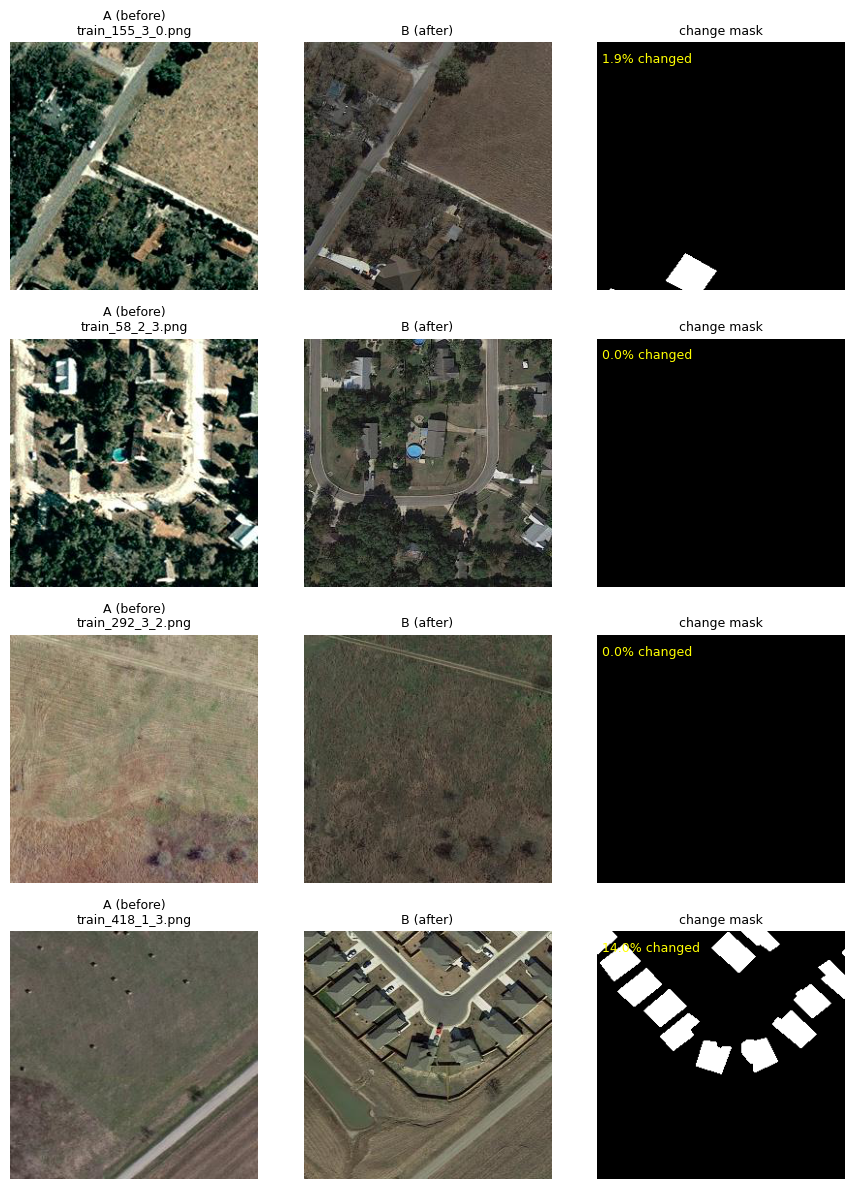

In [12]:
import matplotlib.pyplot as plt

for split in DATA["splits"]:
    print(f"{split:<5} {len(ChangeDetectionDataset(split)):>5} tiles")

# Unnormalized so the images display with natural colours.
loader = make_loader("train", batch_size=4, train=True, num_workers=2)
a, b, m, names = next(iter(loader))
print(f"\nA {tuple(a.shape)} {a.dtype} range [{a.min():.2f}, {a.max():.2f}]")
print(f"B {tuple(b.shape)} {b.dtype}")
print(f"mask {tuple(m.shape)} {m.dtype} values {sorted(m.unique().tolist())}")
assert a.shape == b.shape == (4, 3, 256, 256) and m.shape == (4, 1, 256, 256)
assert set(m.unique().tolist()) <= {0.0, 1.0}

# Paired augmentation: feed identical, asymmetric content as A, B and mask, check it stays aligned.
probe = torch.arange(16.0).view(1, 4, 4)
aug = PairedAugment()
for _ in range(20):
    pa, pb, pm = aug(probe.repeat(3, 1, 1), probe.repeat(3, 1, 1), probe.clone())
    assert torch.equal(pa, pb) and torch.equal(pa[0], pm[0])
print("OK   A, B and mask receive identical flips/rotations")

fig, axes = plt.subplots(len(names), 3, figsize=(9, 3 * len(names)))
for i, name in enumerate(names):
    for ax, img, title in zip(axes[i], (a[i], b[i], m[i]), ("A (before)", "B (after)", "change mask")):
        if img.shape[0] == 3:
            ax.imshow(img.permute(1, 2, 0).numpy())
        else:
            ax.imshow(img[0].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{title}\n{name}" if title.startswith("A") else title, fontsize=9)
        ax.axis("off")
    axes[i, 2].text(5, 20, f"{m[i].mean().item():.1%} changed", color="yellow", fontsize=9)
plt.tight_layout()
fig.savefig(PATHS.figures / "task3_sample_batch.png", dpi=120, bbox_inches="tight")
plt.show()

## Task 4 · Exploratory data analysis

Reads the 256×256 tiles from Task 3 (local disk) and reports:
- image and tile counts per split
- the fraction of changed pixels per split and per image, and how imbalanced the classes are
- the share of tiles with no change at all
- example tiles with large, small and no change

It then computes the per-channel mean and std of the training images (A and B together, so both dates share one normalization) and saves them to `stats.json` on Drive. The dataset uses this file from here on. The stats are computed once and reused in later sessions; set `CONFIG["eda"]["recompute_stats"] = True` to redo them.

Figures go to `results/figures/` and a summary to `results/eda_summary.json`.

In [13]:
CONFIG["eda"] = {
    "io_workers": 8,
    "recompute_stats": False,  # True recomputes stats.json even if it exists
}


def image_of_tile(tile_name):
    """'train_12_3_1.png' -> 'train_12' (the original 1024x1024 image)."""
    return Path(tile_name).stem.rsplit("_", 2)[0]


def _changed_pixels(path):
    m = np.asarray(Image.open(path))
    return int(m.sum()), int(m.size)


def label_statistics(split):
    """Changed-pixel counts for every tile in a split, plus per-image totals."""
    paths = sorted((PATHS.local_tiles / split / "label").glob("*.png"), key=natural_key)
    with ThreadPoolExecutor(CONFIG["eda"]["io_workers"]) as pool:
        counts = list(pool.map(_changed_pixels, paths))
    tile_names = [p.name for p in paths]
    tile_changed = np.array([c for c, _ in counts], dtype=np.int64)
    tile_pixels = np.array([n for _, n in counts], dtype=np.int64)

    per_image = {}
    for name, c, n in zip(tile_names, tile_changed, tile_pixels):
        img = image_of_tile(name)
        changed, pixels = per_image.get(img, (0, 0))
        per_image[img] = (changed + int(c), pixels + int(n))
    image_names = sorted(per_image, key=natural_key)
    return {
        "tile_names": tile_names,
        "tile_frac": tile_changed / tile_pixels,
        "image_names": image_names,
        "image_frac": np.array([per_image[k][0] / per_image[k][1] for k in image_names]),
        "changed": int(tile_changed.sum()),
        "pixels": int(tile_pixels.sum()),
    }


def _channel_sums(path):
    x = np.asarray(Image.open(path).convert("RGB"), dtype=np.float64).reshape(-1, 3) / 255.0
    return x.sum(0), (x * x).sum(0), x.shape[0]


def channel_sums(split, kind):
    """Per-channel sum, sum of squares and pixel count over one image folder."""
    paths = sorted((PATHS.local_tiles / split / kind).glob("*.png"))
    s, sq, n = np.zeros(3), np.zeros(3), 0
    with ThreadPoolExecutor(CONFIG["eda"]["io_workers"]) as pool:
        for a, b, c in pool.map(_channel_sums, paths):
            s += a
            sq += b
            n += c
    return s, sq, n


def mean_std(s, sq, n):
    mean = s / n
    std = np.sqrt(np.maximum(sq / n - mean**2, 0.0))
    return mean, std


def compute_train_stats():
    """Channel mean/std over train A and B tiles, combined and per date."""
    sums = {kind: channel_sums("train", kind) for kind in ("A", "B")}
    combined = tuple(sums["A"][i] + sums["B"][i] for i in range(3))
    mean, std = mean_std(*combined)
    stats = {
        "mean": mean.round(6).tolist(),
        "std": std.round(6).tolist(),
        "per_date": {},
        "source": "train tiles, A and B combined, RGB in [0, 1]",
        "pixels": int(combined[2]),
    }
    for kind, s in sums.items():
        m, sd = mean_std(*s)
        stats["per_date"][kind] = {"mean": m.round(6).tolist(), "std": sd.round(6).tolist()}
    return stats


def write_json(obj, path):
    """Write JSON via a temporary file, so a disconnect never leaves a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".partial")
    tmp.write_text(json.dumps(obj, indent=2))
    os.replace(tmp, path)

In [14]:
t0 = time.time()
LABEL_STATS = {split: label_statistics(split) for split in DATA["splits"]}
print(f"Read label tiles in {time.time() - t0:.0f}s")
print()

header = f"{'split':<6}{'images':>7}{'tiles':>7}{'changed px':>12}{'no-change tiles':>17}{'median img':>12}{'max img':>9}"
print(header)
print("-" * len(header))
eda_summary = {}
for split, st in LABEL_STATS.items():
    row = {
        "images": len(st["image_names"]),
        "tiles": len(st["tile_names"]),
        "changed_pixel_fraction": st["changed"] / st["pixels"],
        "no_change_tile_fraction": float((st["tile_frac"] == 0).mean()),
        "no_change_image_fraction": float((st["image_frac"] == 0).mean()),
        "median_image_changed_fraction": float(np.median(st["image_frac"])),
        "max_image_changed_fraction": float(st["image_frac"].max()),
    }
    eda_summary[split] = row
    print(f"{split:<6}{row['images']:>7}{row['tiles']:>7}{row['changed_pixel_fraction']:>12.2%}"
          f"{row['no_change_tile_fraction']:>17.1%}{row['median_image_changed_fraction']:>12.2%}"
          f"{row['max_image_changed_fraction']:>9.1%}")

train = LABEL_STATS["train"]
neg_pos_ratio = (train["pixels"] - train["changed"]) / max(train["changed"], 1)
eda_summary["train_negative_to_positive_ratio"] = neg_pos_ratio
print()
print(f"Train class ratio: {neg_pos_ratio:.1f} unchanged pixels per changed pixel")
print("(Task 6 loss: BCE + Dice. Dice is not swamped by this imbalance; a BCE pos_weight could use this ratio.)")

write_json(eda_summary, PATHS.results / "eda_summary.json")
print("Saved", PATHS.results / "eda_summary.json")

Read label tiles in 4s

split  images  tiles  changed px  no-change tiles  median img  max img
----------------------------------------------------------------------
train     445   7120       4.59%            55.5%       2.60%    24.8%
val        64   1024       4.20%            57.4%       3.10%    20.4%
test      128   2048       5.09%            54.3%       3.73%    25.1%

Train class ratio: 20.8 unchanged pixels per changed pixel
(Task 6 loss: BCE + Dice. Dice is not swamped by this imbalance; a BCE pos_weight could use this ratio.)
Saved /content/drive/MyDrive/levir-change-detection/results/eda_summary.json


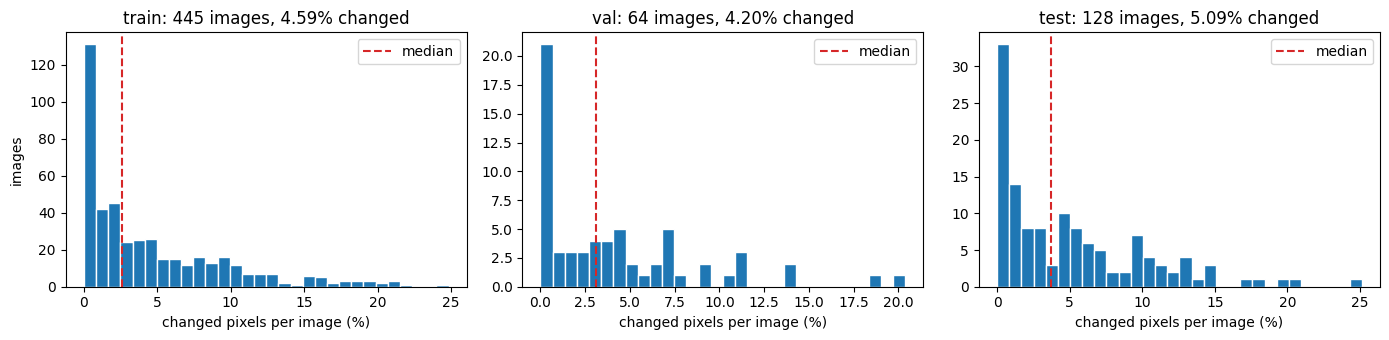

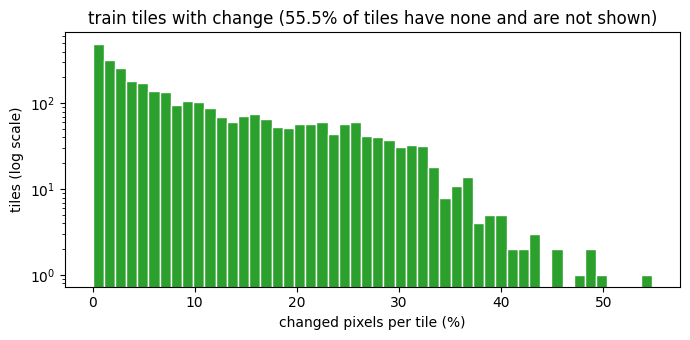

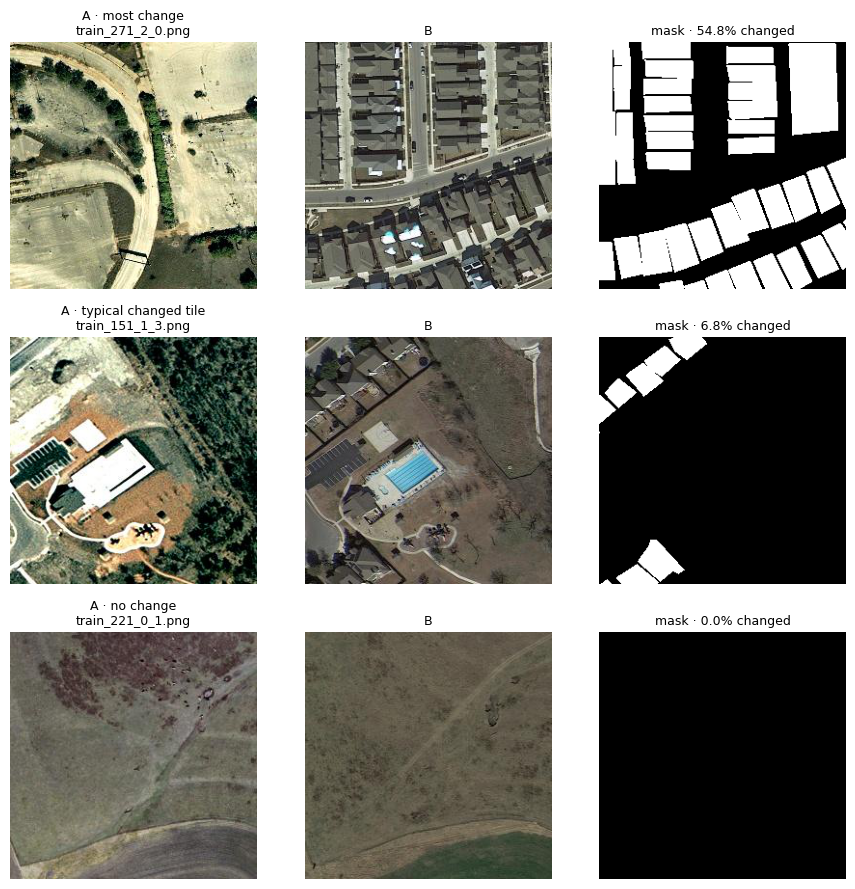

In [15]:
import matplotlib.pyplot as plt

# 1. Per-image changed fraction, one panel per split
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=False)
for ax, (split, st) in zip(axes, LABEL_STATS.items()):
    ax.hist(st["image_frac"] * 100, bins=30, color="tab:blue", edgecolor="white")
    ax.axvline(np.median(st["image_frac"]) * 100, color="tab:red", ls="--", label="median")
    ax.set_title(f"{split}: {len(st['image_names'])} images, {st['changed'] / st['pixels']:.2%} changed")
    ax.set_xlabel("changed pixels per image (%)")
    ax.legend()
axes[0].set_ylabel("images")
plt.tight_layout()
fig.savefig(PATHS.figures / "task4_image_change_hist.png", dpi=120, bbox_inches="tight")
plt.show()

# 2. Per-tile changed fraction in train (log scale: most tiles have little or no change)
tile_frac = train["tile_frac"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(tile_frac[tile_frac > 0] * 100, bins=50, color="tab:green", edgecolor="white")
ax.set_yscale("log")
ax.set_xlabel("changed pixels per tile (%)")
ax.set_ylabel("tiles (log scale)")
ax.set_title(f"train tiles with change ({(tile_frac == 0).mean():.1%} of tiles have none and are not shown)")
plt.tight_layout()
fig.savefig(PATHS.figures / "task4_tile_change_hist.png", dpi=120, bbox_inches="tight")
plt.show()

# 3. Example train tiles: most change, a typical changed tile, and no change
order = np.argsort(tile_frac)
changed_idx = order[tile_frac[order] > 0]
examples = {
    "most change": order[-1],
    "typical changed tile": changed_idx[len(changed_idx) // 2],
    "no change": order[0],
}
fig, axes = plt.subplots(len(examples), 3, figsize=(9, 3 * len(examples)))
train_dir = PATHS.local_tiles / "train"
for row, (label, idx) in zip(axes, examples.items()):
    name = train["tile_names"][idx]
    images = (Image.open(train_dir / "A" / name), Image.open(train_dir / "B" / name), Image.open(train_dir / "label" / name))
    titles = (f"A · {label}\n{name}", "B", f"mask · {tile_frac[idx]:.1%} changed")
    for ax, img, title in zip(row, images, titles):
        if img.mode == "L":
            ax.imshow(np.asarray(img), cmap="gray", vmin=0, vmax=1)
        else:
            ax.imshow(img)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.tight_layout()
fig.savefig(PATHS.figures / "task4_example_tiles.png", dpi=120, bbox_inches="tight")
plt.show()

In [16]:
if PATHS.stats_file.exists() and not CONFIG["eda"]["recompute_stats"]:
    print("Using existing", PATHS.stats_file)
else:
    t0 = time.time()
    print("Computing channel mean/std over train A and B tiles...")
    write_json(compute_train_stats(), PATHS.stats_file)
    print(f"Saved {PATHS.stats_file} ({time.time() - t0:.0f}s)")

STATS = load_stats()
print()
print(f"{'':<10}{'R':>8}{'G':>8}{'B':>8}")
print(f"{'mean':<10}" + "".join(f"{v:>8.4f}" for v in STATS["mean"]))
print(f"{'std':<10}" + "".join(f"{v:>8.4f}" for v in STATS["std"]))
for kind in ("A", "B"):
    print(f"{'mean ' + kind:<10}" + "".join(f"{v:>8.4f}" for v in STATS["per_date"][kind]["mean"]))
print("(mean A vs mean B shows the overall brightness/colour shift between the two dates)")

Using existing /content/drive/MyDrive/levir-change-detection/data/stats.json

                 R       G       B
mean        0.3979  0.3924  0.3351
std         0.1968  0.1879  0.1732
mean A      0.4503  0.4467  0.3813
mean B      0.3455  0.3382  0.2888
(mean A vs mean B shows the overall brightness/colour shift between the two dates)


### Demo: normalized batches

Loads 640 randomly chosen training tiles with the new stats. After normalization each channel should have a mean near 0 and a std near 1. They won't be exact because only a sample is checked.

In [17]:
from torch.utils.data import Subset

# A random sample of tiles. Tiles in file order come from only a few images and regions.
check_ds = ChangeDetectionDataset("train", stats=STATS)
sample = torch.randperm(len(check_ds), generator=torch.Generator().manual_seed(CONFIG["seed"]))[:640]
check_loader = DataLoader(Subset(check_ds, sample.tolist()), batch_size=32, num_workers=2)
s, sq, n = torch.zeros(3, dtype=torch.float64), torch.zeros(3, dtype=torch.float64), 0
for a, b, m, _ in check_loader:
    x = torch.cat([a, b]).double()
    s += x.sum(dim=(0, 2, 3))
    sq += (x * x).sum(dim=(0, 2, 3))
    n += x.shape[0] * x.shape[2] * x.shape[3]
mean = s / n
std = (sq / n - mean**2).clamp_min(0).sqrt()
print("normalized mean:", [round(v, 3) for v in mean.tolist()])
print("normalized std: ", [round(v, 3) for v in std.tolist()])
assert torch.isfinite(mean).all() and torch.isfinite(std).all()
assert (mean.abs() < 0.2).all() and ((std - 1).abs() < 0.2).all(), "normalization looks wrong"
print("OK   dataset loads stats.json and normalizes A and B")

normalized mean: [0.001, -0.002, -0.001]
normalized std:  [1.015, 1.014, 1.012]
OK   dataset loads stats.json and normalizes A and B


## Task 5 · Image-difference baseline

No learning: a pixel is marked as changed when the two dates differ by more than a threshold.

**Score.** Per pixel, the L2 norm of A − B across the RGB channels (images in [0, 1]). Three variants:

| Variant | What it does | Why |
|---|---|---|
| `raw` | plain \|A − B\| | the simplest baseline |
| `matched` | standardize each tile's channels (subtract its mean, divide by its std) separately for A and B, then difference | Task 4 showed A is about 0.10 brighter than B overall; matching removes that global shift |
| `matched_smooth` | `matched`, then a Gaussian blur (σ = 2 px) of the score | suppresses isolated noisy pixels |

**Threshold.** Two rules per variant:
- `val_f1`: the threshold that maximizes F1 on the **val** split. Found exactly from score histograms of changed and unchanged pixels (2,000 bins), so every threshold is tried in a single pass.
- `otsu`: Otsu's method on the val score histogram. It uses no labels, so it shows what a fully unsupervised rule gets.

The test split is used only once, to score the fixed thresholds. Results go to `results/baseline.json` and `results/baseline_per_image.csv` (per original 1024×1024 image). Computed once; set `CONFIG["baseline"]["recompute"] = True` to redo.

In [18]:
import csv

import torch.nn.functional as F

CONFIG["baseline"] = {
    # max_score: top of the histogram range. Larger scores are clipped into the last bin.
    "variants": {
        "raw": {"match": False, "sigma": 0.0, "max_score": 1.75},  # sqrt(3) is the largest possible
        "matched": {"match": True, "sigma": 0.0, "max_score": 10.0},
        "matched_smooth": {"match": True, "sigma": 2.0, "max_score": 10.0},
    },
    "methods": ("val_f1", "otsu"),
    "bins": 2000,
    "batch_size": 64,
    "num_workers": 2,
    "recompute": False,
}
BL = CONFIG["baseline"]


def gaussian_blur(x, sigma):
    """Separable Gaussian blur of an (N, 1, H, W) tensor with reflect padding."""
    if sigma <= 0:
        return x
    radius = max(1, int(round(3 * sigma)))
    t = torch.arange(-radius, radius + 1, dtype=x.dtype, device=x.device)
    k = torch.exp(-(t**2) / (2 * sigma**2))
    k = k / k.sum()
    x = F.pad(x, (radius, radius, radius, radius), mode="reflect")
    x = F.conv2d(x, k.view(1, 1, 1, -1))
    return F.conv2d(x, k.view(1, 1, -1, 1))


def standardize_per_tile(x, eps=1e-6):
    """Zero mean, unit std per tile and channel for an (N, C, H, W) batch."""
    mean = x.mean(dim=(2, 3), keepdim=True)
    std = x.std(dim=(2, 3), keepdim=True)
    return (x - mean) / (std + eps)


def difference_score(a, b, match=False, sigma=0.0):
    """(N, 1, H, W) change score: L2 norm of A - B over channels."""
    if match:
        a, b = standardize_per_tile(a), standardize_per_tile(b)
    score = (a - b).pow(2).sum(dim=1, keepdim=True).sqrt()
    return gaussian_blur(score, sigma)


def baseline_loader(split):
    """Unaugmented, unnormalized tiles (RGB in [0, 1]) in file order."""
    return DataLoader(ChangeDetectionDataset(split), batch_size=BL["batch_size"], shuffle=False,
                      num_workers=BL["num_workers"], pin_memory=torch.cuda.is_available())


def variant_scores(a, b):
    """Scores for every variant, clipped to its histogram range."""
    out = {}
    for name, v in BL["variants"].items():
        s = difference_score(a, b, v["match"], v["sigma"])
        out[name] = s.clamp(0, v["max_score"] * (1 - 1e-6))
    return out


@torch.no_grad()
def score_histograms(split):
    """Histograms of scores for changed (pos) and unchanged (neg) pixels, per variant."""
    bins = BL["bins"]
    hists = {name: {"pos": torch.zeros(bins, dtype=torch.float64, device=DEVICE),
                    "neg": torch.zeros(bins, dtype=torch.float64, device=DEVICE)}
             for name in BL["variants"]}
    for a, b, m, _ in baseline_loader(split):
        a, b = a.to(DEVICE, non_blocking=True), b.to(DEVICE, non_blocking=True)
        pos = m.to(DEVICE).bool()
        for name, s in variant_scores(a, b).items():
            hi = BL["variants"][name]["max_score"]
            for key, sel in (("pos", pos), ("neg", ~pos)):
                if sel.any():
                    hists[name][key] += torch.histc(s[sel], bins=bins, min=0, max=hi).double()
    return hists


def best_f1_threshold(pos, neg, max_score):
    """Threshold (predict change when score >= t) with the highest F1, and that F1."""
    tp = pos.flip(0).cumsum(0).flip(0)  # tp[k]: changed pixels in bins >= k
    fp = neg.flip(0).cumsum(0).flip(0)
    fn = pos.sum() - tp
    f1 = 2 * tp / (2 * tp + fp + fn).clamp_min(1)
    k = int(f1.argmax())
    return k * max_score / len(pos), float(f1[k])


def otsu_threshold(hist, max_score):
    """Otsu's threshold on a histogram (maximizes between-class variance, no labels)."""
    bins = len(hist)
    p = hist / hist.sum()
    centers = (torch.arange(bins, dtype=torch.float64, device=hist.device) + 0.5) * max_score / bins
    omega = p.cumsum(0)
    mu = (p * centers).cumsum(0)
    between = (mu[-1] * omega - mu) ** 2 / (omega * (1 - omega)).clamp_min(1e-12)
    return (int(between.argmax()) + 1) * max_score / bins


def tile_counts(pred, target):
    """[tp, fp, fn, tn] for each tile in a batch, as a list of lists."""
    p, t = pred.bool().flatten(1), target.bool().flatten(1)
    tp = (p & t).sum(1)
    fp = (p & ~t).sum(1)
    fn = (~p & t).sum(1)
    tn = p.shape[1] - tp - fp - fn
    return torch.stack([tp, fp, fn, tn], 1).tolist()


@torch.no_grad()
def evaluate_thresholds(split, thresholds):
    """Confusion counts per original image for each (variant, method) threshold."""
    counts = {key: {} for key in thresholds}
    for a, b, m, names in baseline_loader(split):
        a, b, m = (x.to(DEVICE, non_blocking=True) for x in (a, b, m))
        scores = variant_scores(a, b)
        for (variant, method), thr in thresholds.items():
            per_tile = tile_counts(scores[variant] >= thr, m)
            image_counts = counts[(variant, method)]
            for name, c in zip(names, per_tile):
                img = image_of_tile(name)
                prev = image_counts.get(img, [0, 0, 0, 0])
                image_counts[img] = [x + y for x, y in zip(prev, c)]
    return counts

In [19]:
baseline_json = PATHS.results / "baseline.json"
baseline_csv = PATHS.results / "baseline_per_image.csv"

if baseline_json.exists() and not BL["recompute"]:
    BASELINE = json.loads(baseline_json.read_text())
    print("Using existing", baseline_json)
else:
    t0 = time.time()
    print("Building val score histograms...")
    val_hists = score_histograms("val")
    thresholds, val_info = {}, {}
    for name, h in val_hists.items():
        hi = BL["variants"][name]["max_score"]
        thr, f1 = best_f1_threshold(h["pos"], h["neg"], hi)
        thresholds[(name, "val_f1")] = thr
        val_info[(name, "val_f1")] = f1
        thr_otsu = otsu_threshold(h["pos"] + h["neg"], hi)
        thresholds[(name, "otsu")] = thr_otsu
        # val F1 at the Otsu threshold, from the same histograms
        k = int(round(thr_otsu / hi * BL["bins"]))
        tp = h["pos"][k:].sum()
        fp = h["neg"][k:].sum()
        fn = h["pos"].sum() - tp
        val_info[(name, "otsu")] = float(2 * tp / (2 * tp + fp + fn).clamp_min(1))
    print(f"  done ({time.time() - t0:.0f}s)")

    print("Scoring the test split with the fixed thresholds...")
    test_counts = evaluate_thresholds("test", thresholds)
    print(f"  done ({time.time() - t0:.0f}s)")

    runs, csv_rows = {}, []
    for (variant, method), image_counts in test_counts.items():
        total = [sum(c[i] for c in image_counts.values()) for i in range(4)]
        runs[f"{variant}/{method}"] = {
            "variant": variant,
            "method": method,
            "settings": BL["variants"][variant],
            "threshold": thresholds[(variant, method)],
            "val_f1": val_info[(variant, method)],
            "test": metrics_from_counts(*total),
        }
        for img in sorted(image_counts, key=natural_key):
            csv_rows.append({"run": f"{variant}/{method}", "image": img, **metrics_from_counts(*image_counts[img])})

    # The reported baseline is the run with the best val F1 (test is never used for choosing).
    selected = max(runs, key=lambda k: runs[k]["val_f1"])
    BASELINE = {"selected": selected, "runs": runs, "bins": BL["bins"],
                "note": "thresholds chosen on val; metrics from confusion counts summed over all test pixels"}
    write_json(BASELINE, baseline_json)
    with open(baseline_csv, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(csv_rows[0]))
        writer.writeheader()
        writer.writerows(csv_rows)
    print(f"Saved {baseline_json} and {baseline_csv} ({time.time() - t0:.0f}s)")

print()
header = f"{'run':<24}{'threshold':>10}{'val F1':>8}{'test P':>8}{'test R':>8}{'test F1':>9}{'test IoU':>10}"
print(header)
print("-" * len(header))
for key, r in BASELINE["runs"].items():
    t = r["test"]
    mark = "  <- selected" if key == BASELINE["selected"] else ""
    print(f"{key:<24}{r['threshold']:>10.4f}{r['val_f1']:>8.3f}{t['precision']:>8.3f}{t['recall']:>8.3f}"
          f"{t['f1']:>9.3f}{t['iou']:>10.3f}{mark}")

Using existing /content/drive/MyDrive/levir-change-detection/results/baseline.json

run                      threshold  val F1  test P  test R  test F1  test IoU
-----------------------------------------------------------------------------
raw/val_f1                  0.7026   0.131   0.106   0.174    0.132     0.070  <- selected
raw/otsu                    0.4209   0.108   0.069   0.377    0.116     0.062
matched/val_f1              2.2350   0.096   0.065   0.316    0.108     0.057
matched/otsu                2.2600   0.096   0.065   0.311    0.108     0.057
matched_smooth/val_f1       2.2200   0.110   0.076   0.271    0.119     0.063
matched_smooth/otsu         2.0850   0.109   0.074   0.315    0.120     0.064


### Demo: overlays

Test tiles scored with the selected baseline. Overlay colours: **white** = correct change (TP), **red** = false alarm (FP), **blue** = missed change (FN), black = correct no-change. Tasks 8 and 9 reuse `error_overlay`. Saved to `results/figures/task5_baseline_overlays.png`.

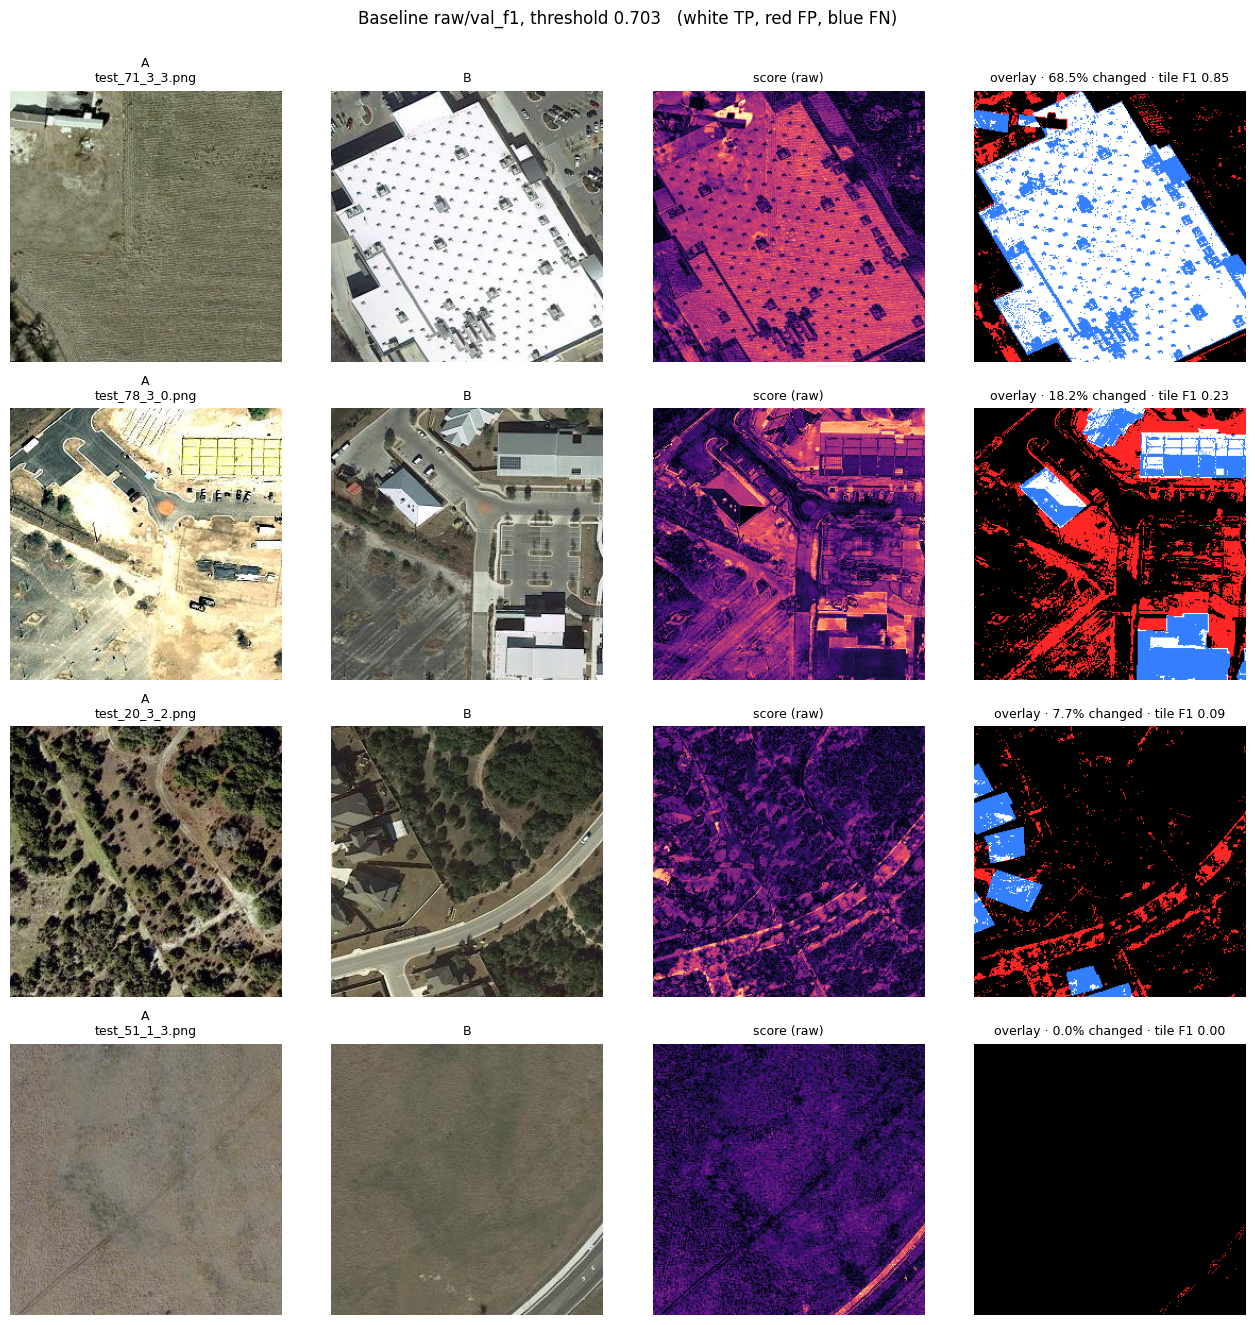

In [20]:
def error_overlay(pred, target):
    """RGB image: white TP, red FP, blue FN, black TN."""
    p = np.asarray(pred).astype(bool)
    t = np.asarray(target).astype(bool)
    rgb = np.zeros(p.shape + (3,), dtype=np.float32)
    rgb[p & t] = (1.0, 1.0, 1.0)
    rgb[p & ~t] = (1.0, 0.15, 0.15)
    rgb[~p & t] = (0.2, 0.5, 1.0)
    return rgb


sel = BASELINE["runs"][BASELINE["selected"]]
v = BL["variants"][sel["variant"]]
test_ds = ChangeDetectionDataset("test")

# Tiles with the most change, upper-quartile and median change, and no change (from Task 4).
test_stats = LABEL_STATS["test"]
frac = test_stats["tile_frac"]
order = np.argsort(frac)
changed = order[frac[order] > 0]
picks = [order[-1], changed[int(len(changed) * 0.75)], changed[len(changed) // 2], order[0]]

fig, axes = plt.subplots(len(picks), 4, figsize=(13, 3.3 * len(picks)))
for row, idx in zip(axes, picks):
    name = test_stats["tile_names"][idx]
    a, b, m, _ = test_ds[test_ds.names.index(name)]
    with torch.no_grad():
        s = difference_score(a[None], b[None], v["match"], v["sigma"])[0, 0]
    pred = (s >= sel["threshold"]).numpy()
    tile_f1 = metrics_from_counts(*confusion_counts(pred, m[0].numpy()))["f1"]
    row[0].imshow(a.permute(1, 2, 0).numpy())
    row[0].set_title(f"A\n{name}", fontsize=9)
    row[1].imshow(b.permute(1, 2, 0).numpy())
    row[1].set_title("B", fontsize=9)
    row[2].imshow(s.numpy(), cmap="magma")
    row[2].set_title(f"score ({sel['variant']})", fontsize=9)
    row[3].imshow(error_overlay(pred, m[0].numpy()))
    row[3].set_title(f"overlay · {frac[idx]:.1%} changed · tile F1 {tile_f1:.2f}", fontsize=9)
    for ax in row:
        ax.axis("off")
fig.suptitle(f"Baseline {BASELINE['selected']}, threshold {sel['threshold']:.3f}   "
             "(white TP, red FP, blue FN)", y=1.0)
plt.tight_layout()
fig.savefig(PATHS.figures / "task5_baseline_overlays.png", dpi=120, bbox_inches="tight")
plt.show()

## Task 6 · Training infrastructure

Shared by every neural model (U-Net-EF in Task 7, Siamese U-Net in Task 9).

- **Model interface.** `model(a, b)` takes the two normalized images, each (N, 3, H, W), and returns change logits (N, 1, H, W). Models are added to a registry and built by name with `build_model(cfg)`.
- **Loss.** BCE + Dice, both weighted. Dice is computed over the whole batch, so tiles without change don't make it unstable. BCE can take a `pos_weight` (Task 4 printed the class ratio).
- **Optimizer.** AdamW with a cosine learning-rate schedule (stepped per epoch), mixed precision (AMP) on the GPU and gradient clipping.
- **Validation** after each epoch: val loss plus precision, recall, F1 and IoU from Task 2's `ConfusionAccumulator`, at a 0.5 probability threshold. Task 8 tunes the threshold later.
- **Checkpoints on Drive** in `runs/<name>/`: `last.pt` every epoch (model, optimizer, scheduler, AMP scaler, random states, epoch, best F1, history) and `best.pt` when val F1 improves. Files are written under a temporary name and then renamed, so a disconnect can't corrupt them.
- **Resuming.** If `last.pt` exists, `train_run` continues from the next epoch. Each epoch's shuffle order depends only on the seed and the epoch number, so a resumed run sees the same data order as an uninterrupted one. Keep a run's settings unchanged while resuming (the cosine schedule depends on `epochs`); the code warns if they differ.
- **Logs.** `runs/<name>/log.csv` (one row per epoch) and `config.json`.
- **Run control.** `CONFIG["runs"]` holds each run's settings and `RUN` says which ones execute on Run all.

In [21]:
import torch.nn as nn

# ---------------------------------------------------------------- model registry
MODELS = {}


def register_model(name):
    def wrap(cls):
        MODELS[name] = cls
        return cls
    return wrap


def build_model(model_cfg):
    """Build a registered model from {'name': ..., **kwargs}."""
    kwargs = {k: v for k, v in model_cfg.items() if k != "name"}
    name = model_cfg["name"]
    if name not in MODELS:
        raise KeyError(f"Unknown model {name!r}. Registered: {sorted(MODELS)}")
    return MODELS[name](**kwargs)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@register_model("dummy")
class DummyCD(nn.Module):
    """Tiny stand-in model for checking the training loop (replaced in Task 7)."""

    def __init__(self, width=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(6, width, 3, padding=1), nn.BatchNorm2d(width), nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1), nn.BatchNorm2d(width), nn.ReLU(inplace=True),
            nn.Conv2d(width, 1, 1),
        )

    def forward(self, a, b):
        return self.net(torch.cat([a, b], dim=1))


# -------------------------------------------------------------------------- loss
class BCEDiceLoss(nn.Module):
    """bce_weight * BCE + dice_weight * (1 - soft Dice over the batch)."""

    def __init__(self, bce_weight=1.0, dice_weight=1.0, pos_weight=None, smooth=1.0):
        super().__init__()
        self.bce_weight, self.dice_weight, self.smooth = bce_weight, dice_weight, smooth
        pw = torch.tensor([pos_weight], dtype=torch.float32) if pos_weight else None
        self.register_buffer("pos_weight", pw)

    def forward(self, logits, target):
        logits = logits.float()  # compute the loss in full precision under AMP
        bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.pos_weight)
        p = torch.sigmoid(logits)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + self.smooth) / (p.sum() + target.sum() + self.smooth)
        return self.bce_weight * bce + self.dice_weight * dice


# ------------------------------------------------------------------- run settings
TRAIN_DEFAULTS = {
    "epochs": 150,
    "batch_size": 16,
    "lr": 1e-3,
    "min_lr_ratio": 0.01,  # cosine schedule ends at lr * min_lr_ratio
    "weight_decay": 1e-4,
    "bce_weight": 1.0,
    "dice_weight": 1.0,
    "pos_weight": None,
    "grad_clip": 1.0,
    "amp": True,
    "threshold": 0.5,  # probability threshold for validation metrics
    "num_workers": 2,
    "max_train_batches": None,  # limit batches per epoch (quick checks only)
    "max_val_batches": None,
}

CONFIG["runs"] = {
    # Quick check of the loop: 4 short epochs on a subset of batches.
    "dummy": {"model": {"name": "dummy", "width": 16}, "epochs": 4, "lr": 3e-3,
              "max_train_batches": 60, "max_val_batches": 16},
}
RUN = {"dummy": True}  # set to False once the Task 6 demo has passed


def run_config(name):
    return {**TRAIN_DEFAULTS, **CONFIG["runs"][name]}

In [22]:
from torch.optim.lr_scheduler import CosineAnnealingLR

LOG_FIELDS = ("epoch", "lr", "train_loss", "val_loss", "val_precision", "val_recall", "val_f1", "val_iou",
              "epoch_seconds", "is_best")


def atomic_torch_save(obj, path):
    tmp = path.with_name(path.name + ".partial")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def write_log_csv(history, path):
    tmp = path.with_name(path.name + ".partial")
    with open(tmp, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=LOG_FIELDS)
        writer.writeheader()
        writer.writerows(history)
    os.replace(tmp, path)


def rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def set_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())
    if state["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in state["cuda"]])


def autocast(enabled):
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=enabled)


@torch.no_grad()
def evaluate_loader(model, loader, loss_fn=None, threshold=0.5, amp=True, max_batches=None):
    """Mean loss (if loss_fn is given) and dataset-level metrics over a loader."""
    model.eval()
    acc = ConfusionAccumulator()
    loss_sum, batches = torch.zeros((), device=DEVICE), 0
    for i, (a, b, m, _) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        a, b, m = (x.to(DEVICE, non_blocking=True) for x in (a, b, m))
        with autocast(amp):
            logits = model(a, b)
        if loss_fn is not None:
            loss_sum += loss_fn(logits, m)
        acc.update(torch.sigmoid(logits.float()) >= threshold, m)
        batches += 1
    loss = float(loss_sum / max(batches, 1)) if loss_fn is not None else None
    return loss, acc.compute()


def train_run(name, stop_after_epochs=None, max_minutes=None):
    """Train (or resume) the run CONFIG['runs'][name]. Returns the per-epoch history.

    stop_after_epochs stops early after that many epochs in this call, to simulate a
    disconnect in the demo. max_minutes stops before an epoch that would end past that
    budget, so a long run ends cleanly before Colab's session limit; rerun to resume.
    """
    call_start = time.time()
    cfg = run_config(name)
    run_dir = PATHS.run_dir(name)
    run_dir.mkdir(parents=True, exist_ok=True)
    stats = load_stats()
    if stats is None:
        raise RuntimeError("stats.json is missing. Run Task 4 first.")

    set_seed(CONFIG["seed"], CONFIG["deterministic"])
    model = build_model(cfg["model"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = CosineAnnealingLR(optimizer, T_max=cfg["epochs"], eta_min=cfg["lr"] * cfg["min_lr_ratio"])
    use_amp = cfg["amp"] and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    loss_fn = BCEDiceLoss(cfg["bce_weight"], cfg["dice_weight"], cfg["pos_weight"]).to(DEVICE)

    start_epoch, best_f1, history = 1, -1.0, []
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    if last_path.exists():
        ckpt = torch.load(last_path, map_location=DEVICE, weights_only=False)
        changed = sorted(k for k in set(cfg) | set(ckpt["config"]) if cfg.get(k) != ckpt["config"].get(k))
        if changed:
            print(f"WARNING: settings differ from the checkpoint: {changed}. Delete {run_dir} to start over.")
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        set_rng_state(ckpt["rng"])
        start_epoch, best_f1, history = ckpt["epoch"] + 1, ckpt["best_f1"], ckpt["history"]
        print(f"Resuming '{name}' after epoch {ckpt['epoch']} (best val F1 {best_f1:.4f})")
    else:
        (run_dir / "config.json").write_text(json.dumps(cfg, indent=2))
        print(f"Starting '{name}': {cfg['model']['name']}, {count_parameters(model):,} parameters")

    if start_epoch > cfg["epochs"]:
        print(f"'{name}' already finished {cfg['epochs']} epochs (best val F1 {best_f1:.4f})")
        return history

    train_loader = make_loader("train", cfg["batch_size"], train=True, stats=stats, num_workers=cfg["num_workers"])
    val_loader = make_loader("val", cfg["batch_size"], train=False, stats=stats, num_workers=cfg["num_workers"])

    epochs_this_call = 0
    for epoch in range(start_epoch, cfg["epochs"] + 1):
        t0 = time.time()
        train_loader.generator.manual_seed(CONFIG["seed"] + epoch)  # same order with or without resuming
        model.train()
        loss_sum, batches = torch.zeros((), device=DEVICE), 0
        for i, (a, b, m, _) in enumerate(train_loader):
            if cfg["max_train_batches"] is not None and i >= cfg["max_train_batches"]:
                break
            a, b, m = (x.to(DEVICE, non_blocking=True) for x in (a, b, m))
            optimizer.zero_grad(set_to_none=True)
            with autocast(use_amp):
                logits = model(a, b)
            loss = loss_fn(logits, m)
            scaler.scale(loss).backward()
            if cfg["grad_clip"]:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.detach()
            batches += 1
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step()

        val_loss, val = evaluate_loader(model, val_loader, loss_fn, cfg["threshold"], use_amp, cfg["max_val_batches"])
        is_best = val["f1"] > best_f1
        if is_best:
            best_f1 = val["f1"]
            atomic_torch_save({"model": model.state_dict(), "epoch": epoch, "val": val, "config": cfg}, best_path)
        row = {
            "epoch": epoch, "lr": lr, "train_loss": float(loss_sum / max(batches, 1)), "val_loss": val_loss,
            "val_precision": val["precision"], "val_recall": val["recall"], "val_f1": val["f1"],
            "val_iou": val["iou"], "epoch_seconds": round(time.time() - t0, 1), "is_best": is_best,
        }
        history.append(row)
        atomic_torch_save({
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "rng": rng_state(),
            "epoch": epoch, "best_f1": best_f1, "history": history, "config": cfg,
        }, last_path)
        write_log_csv(history, run_dir / "log.csv")
        print(f"epoch {epoch:>3}/{cfg['epochs']}  lr {lr:.2e}  train {row['train_loss']:.4f}  "
              f"val {val_loss:.4f}  F1 {val['f1']:.4f}  IoU {val['iou']:.4f}  "
              f"{row['epoch_seconds']:.0f}s{'  *best' if is_best else ''}")

        epochs_this_call += 1
        if stop_after_epochs is not None and epochs_this_call >= stop_after_epochs:
            print(f"Stopping after {epochs_this_call} epoch(s) as requested")
            break
        if max_minutes is not None and epoch < cfg["epochs"]:
            elapsed = (time.time() - call_start) / 60
            if elapsed + row["epoch_seconds"] / 60 > max_minutes:
                print(f"Stopping: the next epoch would pass the {max_minutes}-minute budget. "
                      f"Rerun to resume from epoch {epoch + 1}.")
                break
    return history

### Demo: train the dummy model, interrupt, resume

1. Deletes `runs/dummy` on Drive (only the dummy run) so the demo starts clean.
2. Trains one epoch, then stops, as if Colab had disconnected.
3. Calls `train_run` again, which resumes from `last.pt` and finishes epochs 2–4.

Checks that the log has epochs 1–4 exactly once and that the training loss went down, then plots the curves. Takes a few minutes. Set `RUN["dummy"] = False` afterwards so Run all skips it.

Part 1: one epoch, then stop
Starting 'dummy': dummy, 3,281 parameters
epoch   1/4  lr 3.00e-03  train 1.5547  val 1.3316  F1 0.3014  IoU 0.1774  18s  *best
Stopping after 1 epoch(s) as requested

Part 2: run again; it should resume from the checkpoint
Resuming 'dummy' after epoch 1 (best val F1 0.3014)
epoch   2/4  lr 2.57e-03  train 1.1949  val 1.1173  F1 0.3336  IoU 0.2002  12s  *best
epoch   3/4  lr 1.52e-03  train 1.0639  val 1.0022  F1 0.3982  IoU 0.2486  11s  *best
epoch   4/4  lr 4.65e-04  train 1.0209  val 0.9815  F1 0.4217  IoU 0.2672  12s  *best

OK   resumed run logged epochs [1, 2, 3, 4]
OK   train loss 1.5547 -> 1.0209
Saved: ['best.pt', 'config.json', 'last.pt', 'log.csv']


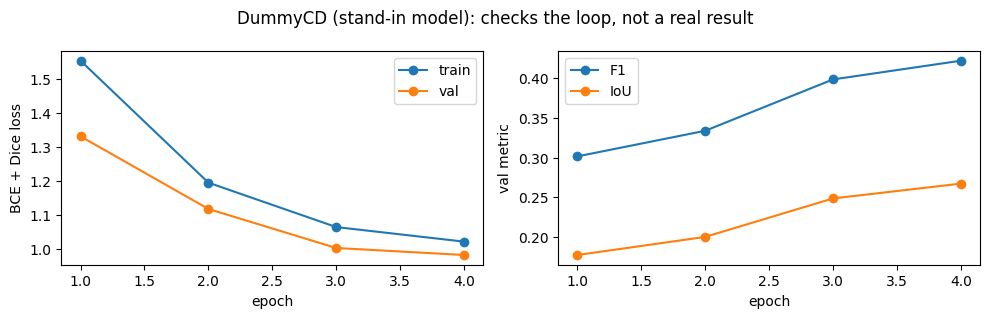

In [23]:
if RUN.get("dummy"):
    shutil.rmtree(PATHS.run_dir("dummy"), ignore_errors=True)

    print("Part 1: one epoch, then stop")
    train_run("dummy", stop_after_epochs=1)
    print()
    print("Part 2: run again; it should resume from the checkpoint")
    history = train_run("dummy")

    n_epochs = run_config("dummy")["epochs"]
    assert [h["epoch"] for h in history] == list(range(1, n_epochs + 1)), "epochs missing or repeated"
    print()
    print("OK   resumed run logged epochs", [h["epoch"] for h in history])
    assert history[-1]["train_loss"] < history[0]["train_loss"], "training loss did not go down"
    print(f"OK   train loss {history[0]['train_loss']:.4f} -> {history[-1]['train_loss']:.4f}")
    print("Saved:", sorted(p.name for p in PATHS.run_dir("dummy").iterdir()))

    ep = [h["epoch"] for h in history]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
    ax1.plot(ep, [h["train_loss"] for h in history], "o-", label="train")
    ax1.plot(ep, [h["val_loss"] for h in history], "o-", label="val")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("BCE + Dice loss")
    ax1.legend()
    ax2.plot(ep, [h["val_f1"] for h in history], "o-", label="F1")
    ax2.plot(ep, [h["val_iou"] for h in history], "o-", label="IoU")
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("val metric")
    ax2.legend()
    fig.suptitle("DummyCD (stand-in model): checks the loop, not a real result")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped (RUN['dummy'] is False)")

## Task 7 · U-Net-EF (early fusion)

A standard U-Net whose input is A and B stacked as 6 channels, so the network compares the two dates from the first layer on (the "FC-EF" design of Daudt et al., 2018).

- **Blocks** (reused by the Siamese U-Net in Task 9): `DoubleConv` (3×3 conv → batch norm → ReLU, twice), `Down` (2×2 max pool → `DoubleConv`), `Up` (2×2 transposed conv → concatenate the skip → `DoubleConv`).
- **Encoder** returns the features of all 5 levels (widths 32, 64, 128, 256, 512). **Decoder** upsamples from the deepest level, merging one skip per level, and ends in a 1×1 conv to 1 logit.
- **Training:** batch 16, lr 1e-3, 150 epochs, BCE + Dice (Task 6 defaults).

**Sessions.** One epoch is 445 batches. 150 epochs take several hours, so the run spans several Colab sessions. Each Run all trains for at most `CONFIG["session_minutes"]` minutes, saves, and moves on to evaluation (Task 8) using the best checkpoint so far. Run all again in a new session and it resumes. Set `RUN["unet_ef"] = False` once it has finished all epochs (it then just reports that it's done).

`DummyCD` stays registered until the Task 6 demo has passed; it isn't used here.

In [24]:
class DoubleConv(nn.Module):
    """(3x3 conv -> batch norm -> ReLU) x 2."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    """2x2 max pool, then DoubleConv."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))

    def forward(self, x):
        return self.block(x)


class Up(nn.Module):
    """2x2 transposed conv, concatenate the skip, then DoubleConv.

    skip_ch is separate from out_ch so the Siamese 'concat' fusion (doubled skips) fits too.
    """

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = DoubleConv(out_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))


class UNetEncoder(nn.Module):
    """Returns the feature maps of every level, shallowest first."""

    def __init__(self, in_channels, widths):
        super().__init__()
        self.inc = DoubleConv(in_channels, widths[0])
        self.downs = nn.ModuleList(Down(widths[i], widths[i + 1]) for i in range(len(widths) - 1))

    def forward(self, x):
        feats = [self.inc(x)]
        for down in self.downs:
            feats.append(down(feats[-1]))
        return feats


class UNetDecoder(nn.Module):
    """Upsamples from the deepest feature map, merging one skip per level, to 1 logit.

    skip_widths and bottom_channels default to widths; the Siamese 'concat' fusion doubles them.
    """

    def __init__(self, widths, skip_widths=None, bottom_channels=None):
        super().__init__()
        skip_widths = list(skip_widths or widths)
        prev = bottom_channels or widths[-1]
        ups = []
        for i in reversed(range(len(widths) - 1)):
            ups.append(Up(prev, skip_widths[i], widths[i]))
            prev = widths[i]
        self.ups = nn.ModuleList(ups)
        self.head = nn.Conv2d(widths[0], 1, kernel_size=1)

    def forward(self, feats):
        x = feats[-1]
        for up, skip in zip(self.ups, reversed(feats[:-1])):
            x = up(x, skip)
        return self.head(x)


@register_model("unet_ef")
class UNetEF(nn.Module):
    """Early fusion: one U-Net on A and B stacked as 6 channels."""

    def __init__(self, in_channels=6, widths=(32, 64, 128, 256, 512)):
        super().__init__()
        self.encoder = UNetEncoder(in_channels, widths)
        self.decoder = UNetDecoder(widths)

    def forward(self, a, b):
        return self.decoder(self.encoder(torch.cat([a, b], dim=1)))


CONFIG["runs"]["unet_ef"] = {
    "model": {"name": "unet_ef", "in_channels": 6, "widths": [32, 64, 128, 256, 512]},
    "epochs": 150,
    "batch_size": 16,
    "lr": 1e-3,
}
RUN["unet_ef"] = True
CONFIG["session_minutes"] = 150  # training time per Run all, before moving on to evaluation


def read_log(name):
    """Per-epoch rows from runs/<name>/log.csv, with numbers parsed."""
    path = PATHS.run_dir(name) / "log.csv"
    if not path.exists():
        return []
    with open(path, newline="") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        for k, v in r.items():
            r[k] = (v == "True") if k == "is_best" else (float(v) if v not in ("", "None") else None)
    return rows


def plot_history(names, save_as=None):
    """Training/validation loss and val F1/IoU for one or more runs."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
    for name in names:
        log = read_log(name)
        if not log:
            continue
        ep = [r["epoch"] for r in log]
        line, = ax1.plot(ep, [r["train_loss"] for r in log], label=f"{name} train")
        ax1.plot(ep, [r["val_loss"] for r in log], ls="--", color=line.get_color(), label=f"{name} val")
        ax2.plot(ep, [r["val_f1"] for r in log], color=line.get_color(), label=f"{name} F1")
        ax2.plot(ep, [r["val_iou"] for r in log], ls=":", color=line.get_color(), label=f"{name} IoU")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("BCE + Dice loss")
    ax1.legend(fontsize=8)
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("val metric (threshold 0.5)")
    ax2.legend(fontsize=8)
    plt.tight_layout()
    if save_as:
        fig.savefig(PATHS.figures / save_as, dpi=120, bbox_inches="tight")
    plt.show()

In [25]:
# Quick check before training: output shape, parameter count, one forward/backward pass.
check_model = build_model(CONFIG["runs"]["unet_ef"]["model"]).to(DEVICE)
x = torch.randn(2, 3, 256, 256, device=DEVICE)
out = check_model(x, x.flip(-1))
assert out.shape == (2, 1, 256, 256), out.shape
out.mean().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in check_model.parameters())
print(f"OK   U-Net-EF output {tuple(out.shape)}, {count_parameters(check_model):,} parameters, gradients finite")
del check_model, x, out
if torch.cuda.is_available():
    torch.cuda.empty_cache()

OK   U-Net-EF output (2, 1, 256, 256), 7,763,905 parameters, gradients finite


In [26]:
if RUN.get("unet_ef"):
    train_run("unet_ef", max_minutes=CONFIG["session_minutes"])
else:
    print("Skipped training (RUN['unet_ef'] is False)")

Resuming 'unet_ef' after epoch 85 (best val F1 0.9010)
epoch  86/150  lr 4.02e-04  train 0.1259  val 0.3357  F1 0.9001  IoU 0.8184  91s
epoch  87/150  lr 3.92e-04  train 0.1230  val 0.3382  F1 0.8972  IoU 0.8136  91s
epoch  88/150  lr 3.82e-04  train 0.1204  val 0.3385  F1 0.8996  IoU 0.8174  91s
epoch  89/150  lr 3.72e-04  train 0.1207  val 0.3259  F1 0.9018  IoU 0.8212  90s  *best
epoch  90/150  lr 3.62e-04  train 0.1212  val 0.3408  F1 0.8968  IoU 0.8129  91s
epoch  91/150  lr 3.52e-04  train 0.1199  val 0.3275  F1 0.9027  IoU 0.8227  91s  *best
epoch  92/150  lr 3.42e-04  train 0.1210  val 0.3261  F1 0.9024  IoU 0.8221  90s
epoch  93/150  lr 3.32e-04  train 0.1189  val 0.3240  F1 0.9020  IoU 0.8215  91s
epoch  94/150  lr 3.23e-04  train 0.1185  val 0.3246  F1 0.9022  IoU 0.8219  92s
epoch  95/150  lr 3.13e-04  train 0.1179  val 0.3364  F1 0.9027  IoU 0.8226  92s
epoch  96/150  lr 3.04e-04  train 0.1185  val 0.3335  F1 0.9032  IoU 0.8235  91s  *best
epoch  97/150  lr 2.94e-04  train

### Demo: training curves

Loss and validation F1/IoU per epoch so far, from `runs/unet_ef/log.csv`, plus the best epoch. Saved to `results/figures/task7_unet_ef_curves.png`.

150/150 epochs done, 183 min of training
best epoch 147: val F1 0.9069  IoU 0.8296  P 0.9148  R 0.8990


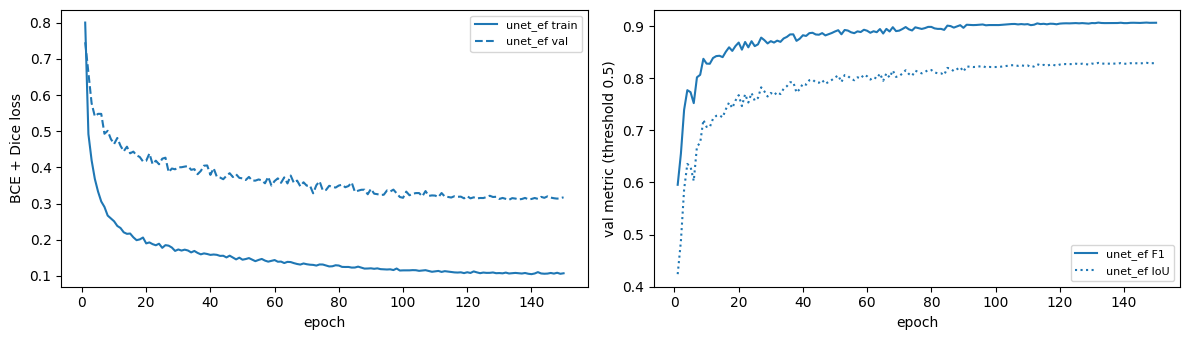

In [27]:
log = read_log("unet_ef")
if log:
    best = max(log, key=lambda r: r["val_f1"])
    total_min = sum(r["epoch_seconds"] for r in log) / 60
    print(f"{len(log)}/{run_config('unet_ef')['epochs']} epochs done, {total_min:.0f} min of training")
    print(f"best epoch {best['epoch']:.0f}: val F1 {best['val_f1']:.4f}  IoU {best['val_iou']:.4f}  "
          f"P {best['val_precision']:.4f}  R {best['val_recall']:.4f}")
    plot_history(["unet_ef"], save_as="task7_unet_ef_curves.png")
else:
    print("No training log yet for unet_ef")

## Task 8 · Evaluation and comparison (Midway Report)

One evaluation path for every trained model, using its `best.pt` (best val F1):

1. **Threshold.** Probabilities on val are binned (1,000 bins) separately for changed and unchanged pixels, and the threshold with the highest val F1 is chosen, as for the baseline. Results at the default 0.5 are kept for reference.
2. **Test.** The fixed threshold is applied to every test tile. Metrics come from confusion counts summed over all test pixels, plus per-image metrics for each of the 128 original images.
3. **Stitching.** Tiles are put back into full 1024×1024 predictions, saved to `results/predictions/<run>/`. As a check, counts from each stitched image must equal the sum of its 16 tile counts.

Outputs: `results/<run>.json`, `results/<run>_per_image.csv` and `results/comparison.csv`. A run is re-evaluated only when its `best.pt` changes (a better epoch was found), or when `CONFIG["eval"]["recompute"]` is True.

Until U-Net-EF finishes training, the numbers reflect the best epoch so far.

In [28]:
CONFIG["eval"] = {
    "batch_size": 32,
    "num_workers": 2,
    "bins": 1000,
    "default_threshold": 0.5,
    "save_predictions": True,
    "recompute": False,
}
EV = CONFIG["eval"]


def load_checkpoint_model(name, which="best"):
    ckpt = torch.load(PATHS.run_dir(name) / f"{which}.pt", map_location=DEVICE, weights_only=False)
    model = build_model(ckpt["config"]["model"]).to(DEVICE)
    model.load_state_dict(ckpt["model"])
    model.eval()
    return model, ckpt


@torch.no_grad()
def predict_batches(model, split, amp=True):
    """Yield (probabilities, masks, names) per batch, in file order."""
    loader = make_loader(split, EV["batch_size"], train=False, stats=load_stats(), num_workers=EV["num_workers"])
    for a, b, m, names in loader:
        a, b = a.to(DEVICE, non_blocking=True), b.to(DEVICE, non_blocking=True)
        with autocast(amp and DEVICE.type == "cuda"):
            logits = model(a, b)
        yield torch.sigmoid(logits.float()), m.to(DEVICE, non_blocking=True), names


def probability_histograms(model, split):
    bins = EV["bins"]
    pos = torch.zeros(bins, dtype=torch.float64, device=DEVICE)
    neg = torch.zeros(bins, dtype=torch.float64, device=DEVICE)
    for p, m, _ in predict_batches(model, split):
        p = p.clamp(0, 1 - 1e-6)
        sel = m.bool()
        if sel.any():
            pos += torch.histc(p[sel], bins=bins, min=0, max=1).double()
        if (~sel).any():
            neg += torch.histc(p[~sel], bins=bins, min=0, max=1).double()
    return pos, neg


def f1_at_threshold(pos, neg, threshold):
    k = int(round(threshold * len(pos)))
    tp, fp = pos[k:].sum(), neg[k:].sum()
    fn = pos.sum() - tp
    return float(2 * tp / (2 * tp + fp + fn).clamp_min(1))


def tile_position(tile_name):
    """'test_7_2_3.png' -> ('test_7', 2, 3)."""
    img, r, c = Path(tile_name).stem.rsplit("_", 2)
    return img, int(r), int(c)


def write_rows_csv(rows, path):
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def evaluate_run(name):
    """Tune the threshold on val, score test, stitch and save predictions. Returns the result dict."""
    out_json = PATHS.results / f"{name}.json"
    model, ckpt = load_checkpoint_model(name)
    if out_json.exists() and not EV["recompute"]:
        prev = json.loads(out_json.read_text())
        if prev.get("checkpoint_epoch") == ckpt["epoch"]:
            print(f"{name}: using existing results (best.pt from epoch {ckpt['epoch']})")
            return prev

    t0 = time.time()
    print(f"{name}: evaluating best.pt from epoch {ckpt['epoch']}")
    pos, neg = probability_histograms(model, "val")
    threshold, val_f1 = best_f1_threshold(pos, neg, 1.0)
    thresholds = {"tuned": threshold, "default": EV["default_threshold"]}
    print(f"  val threshold {threshold:.3f} (val F1 {val_f1:.4f}) ({time.time() - t0:.0f}s)")

    tile, size = DATA["tile_size"], DATA["image_size"]
    tiles_per_image = (size // tile) ** 2
    pred_dir = PATHS.results / "predictions" / name
    pred_dir.mkdir(parents=True, exist_ok=True)
    counts = {key: {} for key in thresholds}
    canvases = {}  # image -> [stitched prediction, stitched label, tiles filled]
    for p, m, names in predict_batches(model, "test"):
        per_key = {key: tile_counts(p >= thr, m) for key, thr in thresholds.items()}
        pred_np = (p >= threshold)[:, 0].cpu().numpy()
        label_np = m[:, 0].bool().cpu().numpy()
        for i, tile_name in enumerate(names):
            img, r, c = tile_position(tile_name)
            for key in thresholds:
                prev = counts[key].get(img, [0, 0, 0, 0])
                counts[key][img] = [x + y for x, y in zip(prev, per_key[key][i])]
            canvas = canvases.setdefault(img, [np.zeros((size, size), bool), np.zeros((size, size), bool), 0])
            ys, xs = slice(r * tile, (r + 1) * tile), slice(c * tile, (c + 1) * tile)
            canvas[0][ys, xs] = pred_np[i]
            canvas[1][ys, xs] = label_np[i]
            canvas[2] += 1
            if canvas[2] == tiles_per_image:
                full = list(confusion_counts(canvas[0], canvas[1]))
                if full != counts["tuned"][img]:
                    raise RuntimeError(f"Stitching check failed for {img}: {full} vs {counts['tuned'][img]}")
                if EV["save_predictions"]:
                    Image.fromarray(canvas[0].astype(np.uint8) * 255).save(pred_dir / f"{img}.png")
                del canvases[img]
    if canvases:
        raise RuntimeError(f"Incomplete images after stitching: {sorted(canvases)[:5]}")

    totals = {key: [sum(c[i] for c in counts[key].values()) for i in range(4)] for key in thresholds}
    log = read_log(name)
    result = {
        "run": name,
        "model": ckpt["config"]["model"],
        "parameters": count_parameters(model),
        "checkpoint_epoch": ckpt["epoch"],
        "epochs_trained": len(log),
        "training_minutes": round(sum(r["epoch_seconds"] for r in log) / 60, 1),
        "threshold": threshold,
        "val_f1": val_f1,
        "val_f1_default_threshold": f1_at_threshold(pos, neg, EV["default_threshold"]),
        "test": metrics_from_counts(*totals["tuned"]),
        "test_default_threshold": metrics_from_counts(*totals["default"]),
        "note": "threshold chosen on val; metrics from confusion counts summed over all test pixels",
    }
    write_json(result, out_json)
    rows = [{"image": img, **metrics_from_counts(*counts["tuned"][img])}
            for img in sorted(counts["tuned"], key=natural_key)]
    write_rows_csv(rows, PATHS.results / f"{name}_per_image.csv")
    print(f"  test F1 {result['test']['f1']:.4f}  IoU {result['test']['iou']:.4f}; "
          f"stitching check passed for {len(rows)} images ({time.time() - t0:.0f}s)")
    del model
    return result


def comparison_table(results):
    """Rows for the selected baseline plus every evaluated model run."""
    rows = []
    baseline_path = PATHS.results / "baseline.json"
    if baseline_path.exists():
        b = json.loads(baseline_path.read_text())
        sel = b["runs"][b["selected"]]
        rows.append({"method": f"baseline ({b['selected']})", "parameters": 0, "epoch": None,
                     "threshold": sel["threshold"],
                     **{k: sel["test"][k] for k in ("precision", "recall", "f1", "iou")}})
    for name, r in results.items():
        rows.append({"method": name, "parameters": r["parameters"], "epoch": r["checkpoint_epoch"],
                     "threshold": r["threshold"],
                     **{k: r["test"][k] for k in ("precision", "recall", "f1", "iou")}})
    return rows

In [29]:
import pandas as pd

EVAL_RESULTS = {}
for name in CONFIG["runs"]:
    if name == "dummy":
        continue
    if (PATHS.run_dir(name) / "best.pt").exists():
        EVAL_RESULTS[name] = evaluate_run(name)
    else:
        print(f"{name}: no best.pt yet, skipped")

table = comparison_table(EVAL_RESULTS)
if table:
    write_rows_csv(table, PATHS.results / "comparison.csv")
    df = pd.DataFrame(table).set_index("method")
    display(df.style.format({"parameters": "{:,.0f}", "epoch": "{:.0f}", "threshold": "{:.3f}",
                             "precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}", "iou": "{:.4f}"},
                            na_rep="-"))
    print("Test set, global metrics. Saved", PATHS.results / "comparison.csv")
else:
    print("Nothing to compare yet")

unet_ef: evaluating best.pt from epoch 147
  val threshold 0.479 (val F1 0.9069) (10s)
  test F1 0.9052  IoU 0.8269; stitching check passed for 128 images (36s)


,parameters,epoch,threshold,precision,recall,f1,iou
method,,,,,,,
baseline (raw/val_f1),0,-,0.703,0.1058,0.1740,0.1316,0.0704
unet_ef,"7,763,905",147,0.479,0.9162,0.8945,0.9052,0.8269


Test set, global metrics. Saved /content/drive/MyDrive/levir-change-detection/results/comparison.csv


### Demo: full-image overlays

For each evaluated model, three test images that contain change: its best, median and worst per-image F1. Columns: A, B, ground truth, overlay (white TP, red FP, blue FN). Saved to `results/figures/task8_<run>_overlays.png`.

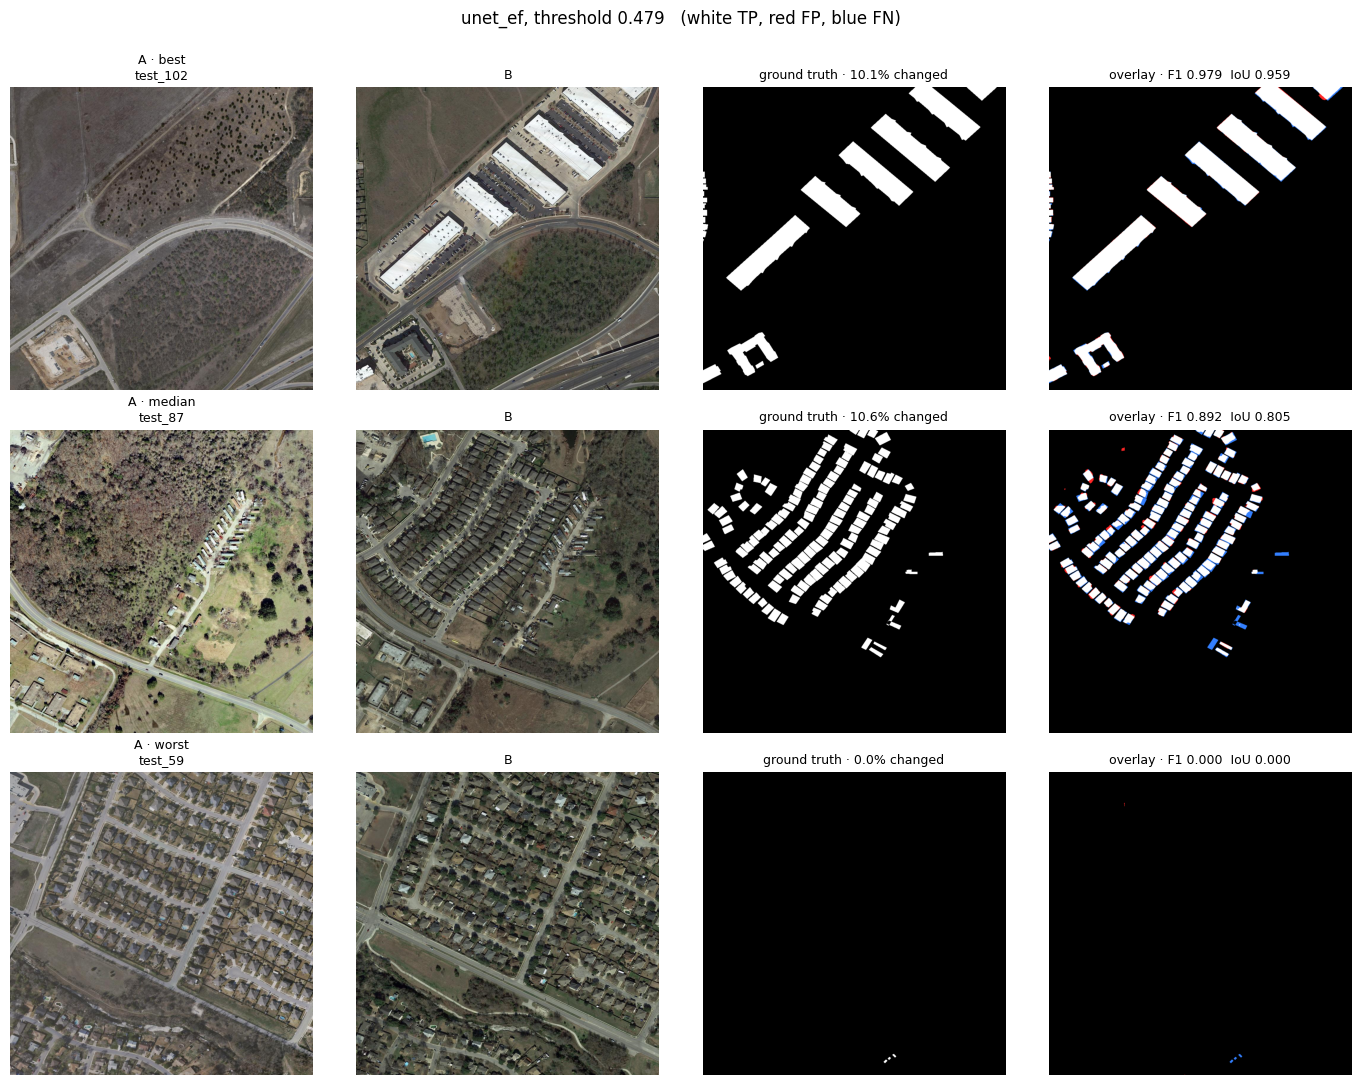

In [30]:
def load_full(split, kind, image):
    """Rebuild a 1024x1024 image (or label) from its 16 local tiles."""
    tile, size = DATA["tile_size"], DATA["image_size"]
    folder = PATHS.local_tiles / split / kind
    tiles = [[np.asarray(Image.open(folder / f"{image}_{r}_{c}.png")) for c in range(size // tile)]
             for r in range(size // tile)]
    return np.concatenate([np.concatenate(row, axis=1) for row in tiles], axis=0)


for name in EVAL_RESULTS:
    pred_dir = PATHS.results / "predictions" / name
    with open(PATHS.results / f"{name}_per_image.csv", newline="") as f:
        per_image = [r for r in csv.DictReader(f) if int(r["tp"]) + int(r["fn"]) > 0]
    per_image.sort(key=lambda r: float(r["f1"]))
    picks = {"best": per_image[-1], "median": per_image[len(per_image) // 2], "worst": per_image[0]}

    fig, axes = plt.subplots(len(picks), 4, figsize=(14, 3.6 * len(picks)))
    for row, (label, r) in zip(axes, picks.items()):
        img = r["image"]
        a, b = load_full("test", "A", img), load_full("test", "B", img)
        gt = load_full("test", "label", img).astype(bool)
        pred = np.asarray(Image.open(pred_dir / f"{img}.png")) > 0
        row[0].imshow(a)
        row[0].set_title(f"A · {label}\n{img}", fontsize=9)
        row[1].imshow(b)
        row[1].set_title("B", fontsize=9)
        row[2].imshow(gt, cmap="gray")
        row[2].set_title(f"ground truth · {gt.mean():.1%} changed", fontsize=9)
        row[3].imshow(error_overlay(pred, gt))
        row[3].set_title(f"overlay · F1 {float(r['f1']):.3f}  IoU {float(r['iou']):.3f}", fontsize=9)
        for ax in row:
            ax.axis("off")
    fig.suptitle(f"{name}, threshold {EVAL_RESULTS[name]['threshold']:.3f}   (white TP, red FP, blue FN)", y=1.0)
    plt.tight_layout()
    fig.savefig(PATHS.figures / f"task8_{name}_overlays.png", dpi=110, bbox_inches="tight")
    plt.show()